# VioGén investigation · Module 3
## From a risk level to an administrative obligation: where does discretion sit in the 2019 and 2025 police protocols?

**Question.** Who decides what, between the recording officer, the system's designers, the specialised police unit, police management, courts, prosecutors and the victim, once VioGén assigns a risk level? And which of the 2019→2025 differences were actually introduced by VioGén-2?

> **Scope.** An institutional reading of two protocol texts, Instrucción 4/2019 and Instrucción 1/2025, plus the instructions issued between them. The automatic risk level is an **input**. It is never computed, and VioGén-2's scoring is neither reconstructed nor approximated. Everything below describes **formal rules**, not what police do. The 50 "pathways" are combinations of rules, not cases.

**Evidence grades.** A = primary text read. B = official government summary. C = secondary source (press, police academy). D = inference from the absence of a rule in the available sources.

### 0 · Setup (the research modules are embedded; the full package adds the PDFs, the extracted texts and the tests)

In [1]:
import hashlib, sys
from pathlib import Path
EMBEDDED = {
    'module3_sources.py': '"""Module 3 source register and clause index (version 2).\n\nEvery clause carries a verbatim Spanish excerpt that the test suite re-finds in the extracted source text on the\ndeclared PDF page(s): exact match for text-layer PDFs (2025, 2021), fuzzy token match (>= 0.90) for the OCR of the\nscanned 2019 PDF. Spanish public-administration instructions are excluded from copyright (art. 13, Texto Refundido\nde la Ley de Propiedad Intelectual), so excerpts are reproduced verbatim; they are still kept short.\n\nPrinted page numbers equal PDF page numbers in all three primary documents (checked page by page).\n"""\nfrom __future__ import annotations\n\nSOURCES = [\n    dict(source_id=\'SES-4-2019\', kind=\'primary\', issuer=\'Secretaría de Estado de Seguridad (Ministerio del Interior)\',\n         title=\'Instrucción 4/2019, por la que se establece un nuevo protocolo para la valoración policial del nivel de riesgo de violencia de género (LO 1/2004), la gestión de la seguridad de las víctimas y seguimiento de los casos a través del Sistema VioGén\',\n         date_signed=\'2019-03-06\', date_effective=\'2019-03-13\', status=\'Left without effect by Instrucción 1/2025 (once fully applicable)\',\n         host=\'violenciagenero.igualdad.gob.es (Delegación del Gobierno contra la Violencia de Género)\', host_type=\'official_government\',\n         url=\'https://violenciagenero.igualdad.gob.es/wp-content/uploads/InstrucciOn_4-2019.pdf\',\n         local_file=\'sources/03_institutional_rules/primary/SES_Instruccion_4-2019_official_igualdad.pdf\',\n         sha256=\'238f9010765c39ed9fc6d59bd5bbee34828dfc558995c0c6c54d85b4fc8d122f\', md5=\'264f0919a6139146dd2c10b14707d906\',\n         pages=23, page_mapping=\'printed page = PDF page (pp. 1-23)\', text_layer=\'none (scanned, Canon iR-ADV C5235, 2019-03-07)\',\n         text_used=\'sources/03_institutional_rules/text/SES_4-2019_OCR_tesseract_spa.txt (Tesseract 5, spa, 200 dpi); clauses checked against page images\',\n         retrieved=\'2026-11-11\', access_note=\'Complete: instruction (pp. 1-4), protocol (pp. 5-14), Anexo 1 measures (pp. 15-18), Anexo 2 PSP (pp. 19-23). The instruction calls the annexes "Adjunto 1/2"; the protocol calls them "Anexo 1/2".\'),\n    dict(source_id=\'SES-1-2025\', kind=\'primary\', issuer=\'Secretaría de Estado de Seguridad (Ministerio del Interior)\',\n         title=\'Instrucción 1/2025, por la que se establece un nuevo protocolo para la valoración y gestión policial del nivel de riesgo de violencia de género y seguimiento de los casos a través del Sistema VioGén-2\',\n         date_signed=\'2025-01-15\', date_effective=\'2025-06-30\', status=\'In force (effective 30 June 2025)\',\n         host=\'mundopolicial.net and academia-geopol.es (byte-identical); avefor.com (different, unstamped binary with identical text)\', host_type=\'third_party_mirror_of_signed_document\',\n         url=\'https://mundopolicial.net/wp-content/uploads/instruccion-1.2025-s.e.s.-viogen.pdf\',\n         local_file=\'sources/03_institutional_rules/primary/SES_Instruccion_1-2025_signed_CSV_mirror.pdf\',\n         sha256=\'08e6c0ecdfc3317a656afb3c92ff5c0fc26ae1ec0ee1aef2216e5a68fca94b00\', md5=\'898f1fc9931acd5173d0dc13a1b24aea\',\n         pages=52, page_mapping=\'printed page "- n -" = PDF page n (pp. 1-52)\', text_layer=\'yes (Word, Quartz PDFContext 2025-01-16)\',\n         text_used=\'sources/03_institutional_rules/text/SES_1-2025_text_layer.txt; Annex II pp. 37-40 and pp. 14-21 also checked visually\',\n         retrieved=\'2026-11-11\',\n         access_note=\'Every page carries CSV GEN-61b6-a6bd-ca9d-fb9e-612a-3074-2815-598b, signer RAFAEL PEREZ RUIZ, 15/01/2025 17:10. The official CSV check (sede.administracion.gob.es/pagSedeFront/servicios/consultaCSV.htm) is captcha-protected and was NOT performed. No government-hosted copy was found. Alternate copy avefor.com sha256 6ddd0b03d4159dad5b4321257717cb46bf8256cbf278664e233585bdd62a6cd6: word-for-word identical body text (6 whitespace-only differences).\'),\n    dict(source_id=\'SES-5-2021\', kind=\'primary\', issuer=\'Secretaría de Estado de Seguridad\',\n         title=\'Instrucción 5/2021, por la que se establece el Protocolo de primer contacto policial con víctimas de violencia de género en situación de desprotección (Protocolo Cero)\',\n         date_signed=\'2021-07-27 (date per DGVG Observatory report 2024, ch. 3 p. 4; not legible in the text layer)\', date_effective=\'on publication\',\n         status=\'Still referenced as in force by Instrucción 1/2025 (not in its derogation list)\',\n         host=\'violenciagenero.igualdad.gob.es\', host_type=\'official_government\',\n         url=\'https://violenciagenero.igualdad.gob.es/wp-content/uploads/PROTOCOLO_CERO.pdf\',\n         local_file=\'sources/03_institutional_rules/primary/SES_Instruccion_5-2021_Protocolo_Cero_official_igualdad.pdf\',\n         sha256=\'1eb535a50b0ee4c230a18a4f44e5029c683b10b3a54fff86614a960c73c87c31\', md5=\'e30cebd5f587d97371d3c2b2ee5ce7fa\',\n         pages=10, page_mapping=\'PDF pages 1-10 (no printed numbers)\', text_layer=\'yes\', text_used=\'sources/03_institutional_rules/text/SES_5-2021_text_layer.txt\',\n         retrieved=\'2026-11-11\', access_note=\'Some header lines are missing from the text layer (print-to-PDF artefacts); clauses used are complete.\'),\n    dict(source_id=\'SES-8-2021\', kind=\'secondary_only\', issuer=\'Secretaría de Estado de Seguridad\',\n         title=\'Instrucción 8/2021, por la que se establecen medidas para prevenir la violencia de género ocasionada por agresores persistentes\',\n         date_signed=\'2021-12-21 (signed "este martes" per press of 21/12/2021)\', date_effective=\'unknown\', status=\'Left without effect by Instrucción 1/2025\',\n         host=\'Text not found publicly. Content from El Periódico de Ceuta, 21/12/2021 (reproduces the Interior communication) and the ISES 1/2023 summary.\',\n         host_type=\'secondary\', url=\'https://www.elperiodicodeceuta.es/interior-endurece-y-amplia-las-medidas-de-control-preventivo-sobre-los-agresores-de-mujeres-reincidentes\',\n         local_file=\'\', sha256=\'\', md5=\'\', pages=\'\', page_mapping=\'\', text_layer=\'\', text_used=\'\', retrieved=\'2026-11-11\', access_note=\'Primary text not accessible.\'),\n    dict(source_id=\'SES-11-2022\', kind=\'secondary_only\', issuer=\'Secretaría de Estado de Seguridad\',\n         title=\'Instrucción 11/2022, por la que se actualizan los procedimientos de actuación en la gestión del riesgo de los denominados "casos resistentes"\',\n         date_signed=\'2022 (announced 16/12/2022)\', date_effective=\'unknown\', status=\'Left without effect by Instrucción 1/2025\',\n         host=\'Official summary only: La Moncloa press release 16/12/2022\', host_type=\'official_summary\',\n         url=\'https://www.lamoncloa.gob.es/serviciosdeprensa/notasprensa/interior/Paginas/2022/161222-grande-marlaska-viogen.aspx\',\n         local_file=\'\', sha256=\'\', md5=\'\', pages=\'\', page_mapping=\'\', text_layer=\'\', text_used=\'\', retrieved=\'2026-11-11\', access_note=\'Primary text not accessible; the press release gives only the purpose (social assistance alongside police protection).\'),\n    dict(source_id=\'SES-1-2023\', kind=\'secondary_only\', issuer=\'Secretaría de Estado de Seguridad\',\n         title=\'Instrucción 1/2023, por la que desarrolla la obligación de comunicación a la víctima de los antecedentes del agresor en los casos de "agresores persistentes" y otras medidas\',\n         date_signed=\'2023-02 (signed "este jueves", press release 09/02/2023)\', date_effective=\'unknown\', status=\'Left without effect by Instrucción 1/2025\',\n         host=\'Official summary: La Moncloa press release 09/02/2023; two-page academy summary (academia-geopol.es, sha256 67a63c39...)\', host_type=\'official_summary\',\n         url=\'https://www.lamoncloa.gob.es/serviciosdeprensa/notasprensa/interior/Paginas/2023/090223-protocolo-alertas-victimas-violencia-genero.aspx\',\n         local_file=\'\', sha256=\'\', md5=\'\', pages=\'\', page_mapping=\'\', text_layer=\'\', text_used=\'\', retrieved=\'2026-11-11\', access_note=\'Summary: https://academia-geopol.es/wp-content/uploads/2023/03/INSTRUCCION-SES-OBLIGACION-DE-COMUNICAR-A-LA-VICTIMA-DE-VDG-ANTECEDENTES-DE-AGRESORES-PERSISTENTES.pdf\'),\n    dict(source_id=\'SES-2-2024\', kind=\'secondary_only\', issuer=\'Secretaría de Estado de Seguridad\',\n         title=\'Instrucción 2/2024, por la que se actualizan los criterios y procedimientos para la Inactivación de casos en el Sistema VioGén\',\n         date_signed=\'2024-03 (in effect "hasta el pasado viernes, 8 de marzo de 2024" per La Marea)\', date_effective=\'~2024-03-08\', status=\'Left without effect by Instrucción 1/2025\',\n         host=\'Text restricted (SUP union site: members only). Official summary: Consejo de Ministros 08/03/2024. Details: La Marea 11/03/2024 (quotes the instruction) and DEPOL police academy 13/03/2024.\',\n         host_type=\'official_summary_plus_secondary\',\n         url=\'https://www.lamoncloa.gob.es/consejodeministros/resumenes/Paginas/2024/080324-rp-cministros.aspx\',\n         local_file=\'\', sha256=\'\', md5=\'\', pages=\'\', page_mapping=\'\', text_layer=\'\', text_used=\'\', retrieved=\'2026-11-11\',\n         access_note=\'La Marea: https://lamarea.com/2024/03/11/interior-endurece-los-criterios-para-poder-desactivar-casos-de-violencia-machista-en-viogen ; DEPOL: https://de-pol.es/2024/03/13/actualizan-los-criterios-y-procedimientos-para-la-inactivacion-de-casos-en-el-sistema-viogen/ ; SUP: https://sup.es/actividad_sindical/instruccion-2-2024-por-la-que-se-actualizan-los-criterios-y-procedimientos-para-la-inactivacion-de-casos-en-el-sistema-viogen/\'),\n    dict(source_id=\'SES-7-2019\', kind=\'title_only\', issuer=\'Secretaría de Estado de Seguridad\',\n         title=\'Instrucción 7/2019, sobre incorporación en los atestados por violencia de género de diligencia de situación administrativa de la víctima extranjera en situación irregular\',\n         date_signed=\'2019\', date_effective=\'unknown\', status=\'Left without effect by Instrucción 1/2025 (content consolidated in protocol §9)\',\n         host=\'Title only (derogation list of Instrucción 1/2025, p. 4)\', host_type=\'title_only\', url=\'\', local_file=\'\', sha256=\'\', md5=\'\', pages=\'\', page_mapping=\'\', text_layer=\'\', text_used=\'\', retrieved=\'2026-11-11\', access_note=\'Not searched further: outside the discretion questions of Module 3.\'),\n    dict(source_id=\'SES-12-2018\', kind=\'title_only\', issuer=\'Secretaría de Estado de Seguridad\',\n         title=\'Instrucción 12/2018, sobre el reforzamiento de las actuaciones policiales en materia de valoración de riesgo en los casos de violencia de género y gestión de la seguridad de las víctimas\',\n         date_signed=\'2018\', date_effective=\'unknown\', status=\'Not in the 2025 derogation list; cited by Instrucción 5/2021\',\n         host=\'Cited in Instrucción 5/2021 p. 1 and p. 4\', host_type=\'title_only\', url=\'\', local_file=\'\', sha256=\'\', md5=\'\', pages=\'\', page_mapping=\'\', text_layer=\'\', text_used=\'\', retrieved=\'2026-11-11\', access_note=\'Predates Instrucción 4/2019; part of the 2019 baseline.\'),\n    dict(source_id=\'SES-7-2016\', kind=\'secondary_primary\', issuer=\'Secretaría de Estado de Seguridad\',\n         title=\'Instrucción 7/2016 (previous protocol)\', date_signed=\'2016-07-08\', date_effective=\'2016\', status=\'Replaced by Instrucción 4/2019\',\n         host=\'Quoted in López Ossorio (2016) doctoral thesis, Annex 6, pp. 327-328 (see Module 2)\', host_type=\'quoted_in_thesis\',\n         url=\'https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\', local_file=\'\', sha256=\'\', md5=\'\', pages=\'\', page_mapping=\'\', text_layer=\'\', text_used=\'\', retrieved=\'2026-11-11\',\n         access_note=\'Rule 1.5: automatic level "podrá ser modificado por los agentes al alza" (Module 2 verification).\'),\n    dict(source_id=\'MONCLOA-2025-01-15\', kind=\'official_summary\', issuer=\'La Moncloa / Ministerio del Interior\',\n         title=\'Interior diseña un nuevo modelo de respuesta policial a la violencia de género (press release, 15/01/2025)\', date_signed=\'2025-01-15\', date_effective=\'\', status=\'\',\n         host=\'lamoncloa.gob.es\', host_type=\'official_summary\', url=\'https://www.lamoncloa.gob.es/serviciosdeprensa/notasprensa/interior/Paginas/2025/150125-marlaska-redondo-sistema-viogen-2.aspx\',\n         local_file=\'\', sha256=\'\', md5=\'\', pages=\'\', page_mapping=\'\', text_layer=\'\', text_used=\'\', retrieved=\'2026-11-11\',\n         access_note=\'States the 2025 protocol integrates "toda la normativa e instrucciones dictadas en la materia desde 2018"; mentions recalibrated algorithms and new indicators (not public).\'),\n]\n\n# ---------------------------------------------------------------------------------------------------------------\ndef C(clause_id, source_id, section, pages, quote, summary_en, topic):\n    return dict(clause_id=clause_id, source_id=source_id, section=section, pdf_pages=pages, printed_pages=pages,\n                quote_es=quote, summary_en=summary_en, topic=topic)\n\n\nCLAUSES = [\n    # ======================================================== 2019 (scanned; OCR + page image)\n    C(\'C19-PRE-OVR\', \'SES-4-2019\', \'Preamble (describing the protocols then in force)\', \'2\',\n      \'Nivel de riesgo que podrá ser modificado al alza por los agentes actuantes si, atendiendo a indicios o informaciones que, a su entender, no se han ponderado adecuadamente en los indicadores del Formulario de valoración del Sistema, resultase necesario para una mejor protección de la mujer víctima.\',\n      \'The preamble records that the protocols already in force before 2019 let officers raise the level.\', \'override\'),\n    C(\'C19-EFF\', \'SES-4-2019\', \'Instrucción TERCERA\', \'4\', \'resultando efectiva desde el día 13 de Marzo de 2019\',\n      \'Effective 13 March 2019 (signed Madrid, 6 March 2019).\', \'provenance\'),\n    C(\'C19-PREC\', \'SES-4-2019\', \'Cuestiones preliminares, C\', \'5\',\n      \'En caso de no contar con denuncia de la víctima o de cualquier otra persona, se procederá igualmente de oficio, llevando a cabo las mismas actuaciones o diligencias, así como la valoración policial del riesgo. Estos supuestos de ausencia de denuncia deben hacerse constar expresamente a la Autoridad Judicial y Fiscal.\',\n      \'Without a complaint, police act ex officio, including the risk assessment, and must state the absence of a complaint to the court and prosecutor.\', \'no_complaint\'),\n    C(\'C19-1.1\', \'SES-4-2019\', \'1.1\', \'6\', \'La primera evaluación del riesgo de nueva violencia la realizarán los agentes policiales que instruyan las diligencias y se ocupen de las primeras investigaciones.\',\n      \'The first assessment is made by the officers who instruct the case file.\', \'information\'),\n    C(\'C19-1.3\', \'SES-4-2019\', \'1.3\', \'7\', \'En ningún caso una víctima abandonará las dependencias policiales sin haber sido valorada ni se le hayan asignado las medidas policiales de protección que correspondan conforme al nivel de riesgo resultante.\',\n      \'VPR filled by officers, never by the victim, only with sufficient corroborated information; no victim leaves without assessment and measures.\', \'information\'),\n    C(\'C19-1.4\', \'SES-4-2019\', \'1.4\', \'7\', \'La última y definitiva VPR será la única incluida en diligencias y quedará como consolidada en el Sistema VioGén.\',\n      \'The VPR may be repeated until the file is sent to the court; the last one is the consolidated VPR. No time limit is stated.\', \'initial_assessment\'),\n    C(\'C19-1.5\', \'SES-4-2019\', \'1.5\', \'7\', \'Durante el proceso de valoración no se realizarán preguntas directas a la víctima, salvo en supuestos muy concretos y siempre que falte algún dato muy específico que sólo pueda recabarse por esta vía.\',\n      \'No direct questions to the victim during the assessment, save very specific cases.\', \'information\'),\n    C(\'C19-1.6\', \'SES-4-2019\', \'1.6\', \'7\', \'que podrá ser modificado por los agentes al alza si, a su juicio y atendiendo a indicios que no se reflejen en los indicadores de riesgo del Formulario de valoración, consideran que resulta necesario para una mejor protección de la víctima.\',\n      \'The system assigns no apreciado / bajo / medio / alto / extremo automatically; officers may raise it.\', \'classification_override\'),\n    C(\'C19-1.7\', \'SES-4-2019\', \'1.7\', \'7\', \'se comunicará a la Autoridad Judicial y Fiscal, en forma de Informe automatizado que genera el propio Sistema\',\n      \'Automated report to court and prosecutor (indicators marked Si/No, result), with exceptional diligencias for special-relevance and minors cases.\', \'judicial_reporting\'),\n    C(\'C19-STATES\', \'SES-4-2019\', \'2 (Inactivación de casos)\', \'9\', \'INACTIVOS: No sometidos a control policial directo. Un Caso INACTIVO debe poder ACTIVARSE en cualquier momento si las circunstancias lo aconsejan.\',\n      \'Two states: active (direct police control, measures per level) and inactive.\', \'case_status\'),\n    C(\'C19-2.5\', \'SES-4-2019\', \'2.5\', \'9\', \'implicarán, con carácter general, que el Caso se encuentre en la situación de ACTIVO en el Sistema VioGén.\',\n      \'Bajo, medio, alto and extremo imply, as a general rule, an active case.\', \'case_status\'),\n    C(\'C19-2.6\', \'SES-4-2019\', \'2.6\', \'9\', \'Una Unidad policial podrá INACTIVAR: con carácter general Casos en nivel de riesgo “no apreciado” y excepcionalmente Casos en nivel de riesgo “bajo”, siempre que, para ambos supuestos, se den todas estas premisas:\',\n      \'A unit MAY inactivate no-apreciado cases generally and bajo cases exceptionally if: no judicial measures; circumstances do not advise otherwise in the evaluator\\\'s judgement; for bajo, at least one contact and a reassessment under 5.3 that did not raise the level.\', \'inactivation\'),\n    C(\'C19-2.6.ii\', \'SES-4-2019\', \'2.6.ii\', \'9\', \'Las circunstancias concretas de los Casos, de las víctimas y/o de los agresores, no aconsejen lo contrario a juicio del evaluador.\',\n      \'Negative condition: nothing in the circumstances advises against inactivation, in the evaluator\\\'s judgement.\', \'inactivation\'),\n    C(\'C19-2.6.iii\', \'SES-4-2019\', \'2.6.iii\', \'9\', \'se haya contactado al menos una vez con la víctima y se haya efectuado una reevaluación del riesgo en los términos establecidos en el Apartado 5, punto 5.3, sin que este se haya elevado.\',\n      \'For bajo: one contact and a 5.3 reassessment without the level rising.\', \'inactivation\'),\n    C(\'C19-2.7\', \'SES-4-2019\', \'2.7\', \'9\', \'no localización de la víctima durante mínimo UN mes a pesar de continuar gestiones para averiguar su paradero\',\n      \'Exceptional inactivation, any level: victim not located for at least ONE month, death, departure abroad, custody, analogous; the causes must be recorded.\', \'exceptional_inactivation\'),\n    C(\'C19-2.7-REC\', \'SES-4-2019\', \'2.7\', \'9\', \'En estos supuestos se especificarán en el Sistema VioGén la/s causas concreta/s de la INACTIVACIÓN.\',\n      \'Record the specific causes in VioGén.\', \'exceptional_inactivation\'),\n    C(\'C19-2.8\', \'SES-4-2019\', \'2.8\', \'10\', \'víctima a su protección, siempre que no cuente con Medidas Judiciales/Orden de Protección en vigor.\',\n      \'Inactivation on the victim\\\'s voluntary, manifest and repeated renunciation, any risk level, if no judicial measures.\', \'exceptional_inactivation\'),\n    C(\'C19-2.8-FISCAL\', \'SES-4-2019\', \'2.8\', \'10\', \'En estos supuestos se elevará Informe al Ministerio Fiscal dando cuenta de todos los hechos y circunstancias del Caso que ponen de manifiesto dicha renuncia.\',\n      \'Report to the prosecutor on renunciation.\', \'exceptional_inactivation\'),\n    C(\'C19-REACT\', \'SES-4-2019\', \'2 (closing paragraph)\', \'10\', \'Para todos los supuestos de INACTIVACIÓN, La unidad policial deberá REACTIVAR el Caso si fuera aconsejable por cambio en las circunstancias.\',\n      \'Duty to reactivate when changed circumstances advise it.\', \'reactivation\'),\n    C(\'C19-3.1\', \'SES-4-2019\', \'3.1\', \'10\', \'que serán de aplicación obligatoria e inmediata, según lo establecido en el Anexo 1 del presente Protocolo. Dichas medidas se adaptarán a las circunstancias concretas del Caso\',\n      \'Each level carries mandatory, immediate measures (Anexo 1), adapted to the case.\', \'protection\'),\n    C(\'C19-3.2\', \'SES-4-2019\', \'3.2\', \'10\', \'esta será comunicada expresamente tanto a víctima como a agresor.\',\n      \'A court restraining/protection order is communicated to both victim and aggressor.\', \'judicial\'),\n    C(\'C19-3.3\', \'SES-4-2019\', \'3.3\', \'10\', \'con ocasión de la primera VPER, se le proporcionará un Plan Personalizado de Seguridad Personalizado\',\n      \'The PSP is provided at the first VPER (sic: "Plan Personalizado de Seguridad Personalizado").\', \'psp\'),\n    C(\'C19-3.4\', \'SES-4-2019\', \'3.4\', \'10\', \'desmarcarán aquellas Medidas de autoprotección o incluso Apartados\',\n      \'Officers deselect inapplicable self-protection measures.\', \'psp\'),\n    C(\'C19-4.1\', \'SES-4-2019\', \'4.1\', \'10\', \'el Caso se mantendrá ACTIVO en el Sistema, siendo por tanto de aplicación obligatoria las medidas policiales de protección correspondientes al nivel de riesgo resultante, incluyendo velar por el cumplimiento de las Medidas judiciales dictadas.\',\n      \'With judicial measures the case stays active; police apply level measures and ensure compliance with the order.\', \'judicial\'),\n    C(\'C19-4.2\', \'SES-4-2019\', \'4.2.i\', \'11\', \'y la Autoridad Judicial ha desestimado la Orden de Alejamiento o de Protección, se aplicarán las medidas policiales de protección que correspondan a cada nivel de riesgo, debiendo el Caso permanecer ACTIVO en el Sistema VioGén.\',\n      \'Medio/alto/extremo without a court order (refused) remain active with level measures; no-apreciado and bajo without measures may follow the inactivation rules (4.2.ii).\', \'case_status\'),\n    C(\'C19-4.3\', \'SES-4-2019\', \'4.3\', \'11\', \'Se procederá a informar detalladamente de estos extremos a la Autoridad Judicial y Fiscal\',\n      \'Where the victim renounces or obstructs protection, inform court and prosecutor in detail; promote contact with other institutions.\', \'resistant_cases\'),\n    C(\'C19-4.4\', \'SES-4-2019\', \'4.4\', \'11\', \'podrán ser de aplicación cualesquiera otras que a juicio de los agentes, contribuyan eficazmente a la protección.\',\n      \'All Anexo 1 measures are compulsory; officers may add others.\', \'protection\'),\n    C(\'C19-4.5\', \'SES-4-2019\', \'4.5\', \'11\', \'Esta incidencia debe hacerse constar en el Sistema VioGén\',\n      \'If measures exceed the evaluator\\\'s decision-making/operational capacity, inform those who allocate resources and record the incident.\', \'resources\'),\n    C(\'C19-5.2-C\', \'SES-4-2019\', \'5.2.i\', \'12\', \'Se utilizará cuando se produzca un hecho significativo, como una nueva denuncia (reincidencia policial) o un quebrantamiento.\',\n      \'VPER-C (with incident) for a significant event: new complaint or breach.\', \'trigger\'),\n    C(\'C19-5.2-S\', \'SES-4-2019\', \'5.2.ii\', \'12\', \'así como a solicitud de la Autoridad Judicial o Fiscal.\',\n      \'VPER-S (no incident) while time passes without significant events; MAY also be done on new information or at the request of court/prosecutor.\', \'trigger\'),\n    C(\'C19-5.3\', \'SES-4-2019\', \'5.3\', \'12\', \'la primera VPER se llevará a cabo una vez se desarrolle la primera actuación judicial, del tipo que sea, en la que se resuelva la solicitud de Orden de Alejamiento y/o Medida de Protección, en todo caso en un plazo máximo de SIETE días tras la VPR.\',\n      \'Bajo, medio, alto, extremo: first VPER after the first judicial action resolving the protection request, at most SEVEN days after the VPR.\', \'first_followup\'),\n    C(\'C19-5.4\', \'SES-4-2019\', \'5.4\', \'12\', \'para aquellos casos con nivel de riesgo “no apreciado” que, tras la actuación judicial referida, pasen a contar con Medidas Judiciales/Orden de Protección.\',\n      \'5.3 also applies to no-apreciado cases that obtain judicial measures.\', \'first_followup\'),\n    C(\'C19-5.5\', \'SES-4-2019\', \'5.5\', \'12\', \'la primera VPER se llevará a cabo cuando hayan transcurrido, al menos, SIETE días desde la VPR.\',\n      \'Exceptionally, for cases flagged as specially relevant: first VPER only after AT LEAST seven days (a minimum wait, to allow forensic assessment).\', \'first_followup\'),\n    C(\'C19-5.7\', \'SES-4-2019\', \'5.7\', \'13\', \'Una vez practicada la primera VPER se proporcionará a la víctima su Plan de Seguridad Personalizado\',\n      \'PSP after the first VPER.\', \'psp\'),\n    C(\'C19-5.8\', \'SES-4-2019\', \'5.8\', \'13\', \'Si la nueva denuncia llegara después de un periodo de SEIS meses o más desde la última VALORACIÓN, procederá valorar de nuevo a la víctima con el Formulario VPR.\',\n      \'Inactive case + new complaint against the same aggressor: VPR if six months or more since the last assessment, otherwise VPER-C.\', \'reactivation\'),\n    C(\'C19-5.9\', \'SES-4-2019\', \'5.9\', \'13\', \'con independencia del tiempo transcurrido en INACTIVO, se llevará a cabo la ACTIVACIÓN mediante la realización de una VPER-S.\',\n      \'Reactivation for another reason (prison release, return to Spain, etc.) by VPER-S, whatever the time inactive.\', \'reactivation\'),\n    C(\'C19-POST\', \'SES-4-2019\', \'5 (Posteriores VPER)\', \'13\', \'si el caso evoluciona sin incidentes, se realizarán las siguientes valoraciones VPER-S en tanto en cuanto permanezca ACTIVO\',\n      \'After the first VPER, without incidents, while active: extremo <72 h, alto <7 d, medio <30 d, bajo <60 d, no apreciado <90 d.\', \'periodic_followup\'),\n    C(\'C19-5.10\', \'SES-4-2019\', \'5.10\', \'14\', \'igualmente podrá ser modificado por los agentes al alza si, atendiendo a otros indicios que no estén reflejados en los indicadores del Sistema, considera que resulta necesario para una mejor protección.\',\n      \'The VPER result may likewise be raised by officers.\', \'override\'),\n    C(\'C19-5.11\', \'SES-4-2019\', \'5.11\', \'14\', \'se comunicará a la Autoridad Judicial y Fiscal, de manera individualizada, cuando exista variación en el riesgo\',\n      \'VPER-S result sent individually to court/prosecutor when the risk varies (either direction).\', \'notification\'),\n    C(\'C19-5.12\', \'SES-4-2019\', \'5.12\', \'14\', \'En el caso de que la VPER diera lugar a unas nuevas Diligencias (VPER-C), el resultado de dicha valoración e Informe automatizado que genera el propio Sistema, se incluirá en las diligencias policiales.\',\n      \'VPER-C results go into the new police file.\', \'notification\'),\n    C(\'C19-A1-CUM\', \'SES-4-2019\', \'Anexo 1 (header)\', \'15\', \'conllevarán, además de sus medidas de protección específicas, la aplicación de las previstas para los niveles anteriores que no se encuentren implícitas en ellas.\',\n      \'Measures are cumulative across levels.\', \'protection\'),\n    C(\'C19-A1-EXTRA\', \'SES-4-2019\', \'Anexo 1 (header)\', \'15\', \'podrá ser implementada cualquier otra que a juicio de la unidad policial sea susceptible de aplicación.\',\n      \'The unit may add any other measure.\', \'protection\'),\n    C(\'C19-A2-NOTE\', \'SES-4-2019\', \'Anexo 2 (Nota)\', \'19\', \'El Plan de Seguridad Personalizado se extraerá por primera vez con la primera VPER, con independencia del nivel de riesgo.\',\n      \'PSP first extracted at the first VPER, whatever the level.\', \'psp\'),\n\n    # ======================================================== 2025 (text layer)\n    C(\'C25-OBJ\', \'SES-1-2025\', \'Preamble\', \'2\', \'El objetivo principal de esta nueva Instrucción es integrar y refundir toda la normativa e Instrucciones de la Secretaría de Estado de Seguridad existentes en materia de violencia de género\',\n      \'The 2025 instruction consolidates the earlier SES instructions.\', \'provenance\'),\n    C(\'C25-SEG\', \'SES-1-2025\', \'Instrucción SEGUNDA\', \'3\', \'La persona titular de la Dirección General de Coordinación y Estudios, como responsable del tratamiento y funcionamiento del Sistema de Seguimiento Integral de los Casos de Violencia de Género (Sistema VioGén-2), realizará los cambios técnicos y organizativos oportunos\',\n      \'The Director-General for Coordination and Studies is responsible for the system\\\'s processing and functioning.\', \'design\'),\n    C(\'C25-EFF\', \'SES-1-2025\', \'Instrucción QUINTA\', \'4\', \'resultando efectiva desde el día 30 de junio de 2025.\', \'Effective 30 June 2025.\', \'provenance\'),\n    C(\'C25-DEROG\', \'SES-1-2025\', \'Instrucción QUINTA\', \'4\', \'Una ver resulte totalmente aplicable, quedarán sin efecto los siguientes instrumentos normativos de la Secretaría de Estado de Seguridad:\',\n      \'Once fully applicable, leaves without effect Instrucciones 4/2019, 7/2019, 8/2021, 11/2022, 1/2023 and 2/2024 (sic "Una ver").\', \'provenance\'),\n    C(\'C25-DEF-SUP\', \'SES-1-2025\', \'1 (definitions)\', \'8\', \'Caso sometido a una fase temporal de seguimiento especial antes de su Inactivación definitiva.\',\n      \'Definition of supervised case.\', \'supervision\'),\n    C(\'C25-DEF-EVAL\', \'SES-1-2025\', \'1 (definitions)\', \'8\', \'La estimación policial del riesgo no descansa únicamente en el algoritmo matemático, sino que el Sistema permite que los agentes policiales puedan modificar el resultado cuando cuenten con información que así lo aconseje y realizar las observaciones que consideren.\',\n      \'Definition: officers may modify the result (direction not stated in the definition).\', \'override\'),\n    C(\'C25-DEF-SEMI\', \'SES-1-2025\', \'1 (definitions)\', \'8\', \'Los sistemas semiactuariales de evaluación del riesgo aportan un nivel de riesgo sujeto a modificación por los profesionales una vez obtenido a partir de la combinación algorítmica de los factores de riesgo presentes.\',\n      \'VPR/VPER are described as semi-actuarial (adjusted actuarial) tools.\', \'design\'),\n    C(\'C25-PREL-NODEN\', \'SES-1-2025\', \'1 (Cuestiones preliminares)\', \'10\', \'Si no se dispone de la denuncia de la víctima o de cualquier otra persona, se procederá igualmente de oficio, llevando a cabo las mismas actuaciones o diligencias, así como la valoración policial del riesgo.\',\n      \'Ex officio action and assessment without complaint; state it to court/prosecutor; act under Protocolo Cero.\', \'no_complaint\'),\n    C(\'C25-PREL-FINAL\', \'SES-1-2025\', \'1 (Cuestiones preliminares)\', \'10\', \'La decisión final sobre la valoración del riesgo facilitada por el Sistema Viogén-2 es supervisada y adoptada –ya sea en acuerdo o desacuerdo– por el agente en base a la información disponible, su conocimiento y experiencia, siguiendo las reglas establecidas en el presente Protocolo.\',\n      \'The final decision is adopted by the officer, "in agreement or disagreement", following the protocol\\\'s rules (which provide only upward modification).\', \'override\'),\n    C(\'C25-PREL-NOML\', \'SES-1-2025\', \'1 (Cuestiones preliminares)\', \'10\', \'El Sistema no incorpora mecanismos o procesos de aprendizaje automático, ni adapta sus criterios en base a los resultados de dicho aprendizaje, ni los puntos de corte se modifican con el funcionamiento del Sistema.\',\n      \'No machine learning; cut-offs do not change with operation.\', \'design\'),\n    C(\'C25-PREL-HOM\', \'SES-1-2025\', \'1 (Cuestiones preliminares)\', \'11\', \'Cuando se tenga noticia de un homicidio en el ámbito de violencia de género no se inactivará el Caso si está dado de alta en el Sistema\',\n      \'After a homicide the case is not inactivated; the Central Administration handles it.\', \'inactivation\'),\n    C(\'C25-PREL-NA\', \'SES-1-2025\', \'1 (Cuestiones preliminares)\', \'11\', \'en este Protocolo desaparece el Nivel de riesgo No Apreciado, por lo que los Casos se distribuyen en cuatro niveles de riesgo (Bajo, Medio, Alto y Extremo).\',\n      \'"No apreciado" disappears; four levels.\', \'classification\'),\n    C(\'C25-PREL-BAJO\', \'SES-1-2025\', \'1 (Cuestiones preliminares)\', \'11\', \'el nivel Bajo se subclasifica, a efectos de gestión del riesgo, en dos niveles en virtud de la existencia o no de medidas judiciales en vigor.\',\n      \'Bajo is subdivided for risk management by whether judicial measures are in force.\', \'classification\'),\n    C(\'C25-3.1\', \'SES-1-2025\', \'3.1\', \'13\', \'La primera valoración policial del riesgo será realizada por el personal policial que instruya las diligencias y se ocupe de las primeras investigaciones.\',\n      \'First assessment by the instructing officers; data quality is stressed.\', \'information\'),\n    C(\'C25-3.4\', \'SES-1-2025\', \'3.4\', \'13\', \'El Formulario VPR lo cumplimentará directamente el personal policial actuante, nunca la víctima ni otros implicados, y sólo cuando se recoja información suficiente y contrastada de todas las fuentes disponibles sobre el supuesto concreto.\',\n      \'Officers fill the VPR; never the victim; only with sufficient corroborated information.\', \'information\'),\n    C(\'C25-3.5\', \'SES-1-2025\', \'3.5\', \'13\', \'la valoración y asignación de medidas policiales de protección conforme al nivel de riesgo se realizará independientemente de que haya presentado o no denuncia, actuando conforme al Protocolo Cero.\',\n      \'Assessment completed before the victim leaves; assessment and measures regardless of a complaint (Protocolo Cero).\', \'no_complaint\'),\n    C(\'C25-3.6\', \'SES-1-2025\', \'3.6\', \'13\', \'reduciendo todo lo posible el número de indicadores valorados como No se sabe.\',\n      \'Contrast sources; minimise "No se sabe" answers.\', \'information\'),\n    C(\'C25-3.7\', \'SES-1-2025\', \'3.7\', \'13\', \'La última y definitiva VPR será la única incluida en diligencias y quedará como VPR consolidada en el Sistema VioGén-2, para lo que disponen de un plazo máximo de 72 horas.\',\n      \'Consolidated VPR within a maximum of 72 hours.\', \'initial_assessment\'),\n    C(\'C25-3.8-LEV\', \'SES-1-2025\', \'3.8\', \'14\', \'una vez practicada la valoración por medio del Formulario VPR del Caso concreto, asignará automáticamente uno de los siguientes niveles de riesgo:\',\n      \'The system assigns Bajo / Medio / Alto / Extremo automatically.\', \'classification\'),\n    C(\'C25-3.8\', \'SES-1-2025\', \'3.8\', \'14\', \'podrá ser modificado al alza al final de cada valoración completa y a la vista de la clasificación automática por el personal policial si, a su juicio, y atendiendo a indicios que no se reflejen en los indicadores de riesgo del formulario de valoración, consideran que ello resulta necesario para una mejor protección de la víctima.\',\n      \'Upward modification only, at the end of each complete assessment, on indications not captured by the form.\', \'override\'),\n    C(\'C25-3.8-MEAS\', \'SES-1-2025\', \'3.8\', \'14\', \'En cada uno de los niveles de riesgo resultantes se adoptarán de inmediato las medidas de prevención y protección\',\n      \'Measures adopted immediately at each level.\', \'protection\'),\n    C(\'C25-3.9\', \'SES-1-2025\', \'3.9\', \'14\', \'El resultado de la valoración global se comunicará a la Autoridad Judicial y Fiscal mediante el informe que genera el propio Sistema.\',\n      \'Automated report to court and prosecutor, always with indicators marked Si/No/NS and the result; additional diligencias where applicable.\', \'judicial_reporting\'),\n    C(\'C25-3.9-NS\', \'SES-1-2025\', \'3.9.a\', \'14\', \'de riesgo (marcados Si/No/NS) y el resultado de la valoración.\',\n      \'"No se sabe" answers are visible to the court.\', \'judicial_reporting\'),\n    C(\'C25-3.9-ER\', \'SES-1-2025\', \'3.9.b.i\', \'14\', \'Diligencia de Caso de Especial Relevancia en la que el propio Sistema destaca el Caso por considerarlo potencialmente letal\',\n      \'Automated special-relevance diligencia recommending further judicial assessment.\', \'complex_cases\'),\n    C(\'C25-3.9-MR\', \'SES-1-2025\', \'3.9.b.ii\', \'14\', \'Diligencia de Menores en Riesgo, en la que el propio Sistema destaca el Caso por incluir menores a cargo de la víctima\',\n      \'Automated minors-at-risk diligencia.\', \'complex_cases\'),\n    C(\'C25-3.9-AP\', \'SES-1-2025\', \'3.9.b.iii\', \'14\', \'Diligencia de Caso con Agresor Persistente, donde el Sistema destaca el Caso como tal\',\n      \'Automated persistent-aggressor diligencia.\', \'complex_cases\'),\n    C(\'C25-4.1\', \'SES-1-2025\', \'4.1\', \'15\', \'así como a solicitud de la Autoridad Judicial o Fiscal, siempre que esa solicitud no esté asociada a un posible hecho reincidente, en cuyo supuesto se empleará el Formulario VPR.\',\n      \'VPER during follow-up without reoffending; MUST also be done when new information arises; on court/prosecutor request, VPER unless linked to possible reoffending (then VPR).\', \'trigger\'),\n    C(\'C25-4.2\', \'SES-1-2025\', \'4.2\', \'15\', \'se utilizará también cuando se produzca un hecho significativo, como una nueva denuncia (reincidencia policial) o un quebrantamiento de medidas por el agresor.\',\n      \'VPR (not VPER) for a significant event: new complaint or breach of measures.\', \'trigger\'),\n    C(\'C25-4.3\', \'SES-1-2025\', \'4.3\', \'15\', \'Para los Casos en niveles de riesgo Medio, Alto y Extremo, la primera VPER se llevará a cabo una vez se desarrolle la primera actuación judicial, del tipo que sea, en la que se resuelva la solicitud de orden de alejamiento y/o medida de protección, en todo caso en un plazo máximo de 15 días tras la VPR.\',\n      \'Medio/alto/extremo: first VPER after the first judicial action, at most 15 days after the VPR.\', \'first_followup\'),\n    C(\'C25-4.4\', \'SES-1-2025\', \'4.4\', \'15\', \'para aquellos casos con nivel de riesgo Bajo que, tras la actuación judicial referida, pasen a contar con medidas judiciales, penales u orden de protección.\',\n      \'Same for Bajo cases that obtain judicial measures. Bajo without measures: no first-VPER deadline stated.\', \'first_followup\'),\n    C(\'C25-4.5\', \'SES-1-2025\', \'4.5\', \'15\', \'Excepcionalmente, y sólo para los Casos de Especial Relevancia con niveles de riesgo Medio y Alto, cuyo Informe VPR lleva aparejado una diligencia adicional, la primera VPER se llevará a cabo cuando hayan transcurrido, al menos, 7 días desde la VPR.\',\n      \'Special-relevance cases at Medio/Alto: first VPER only after at least 7 days; Extremo may be reassessed earlier at the specialised officers\\\' judgement.\', \'first_followup\'),\n    C(\'C25-4.5-EXT\', \'SES-1-2025\', \'4.5\', \'15\', \'El nivel de riesgo Extremo podrá ser reevaluado con antelación, a juicio del personal policial especializado\',\n      \'Extremo special-relevance cases may be reassessed earlier.\', \'first_followup\'),\n    C(\'C25-5.1\', \'SES-1-2025\', \'5.1\', \'15\', \'que serán de aplicación obligatoria e inmediata, según lo establecido en el Anexo II del presente Protocolo.\',\n      \'Mandatory, immediate measures per Annex II, personalised and clearly communicated.\', \'protection\'),\n    C(\'C25-5.2\', \'SES-1-2025\', \'5.2\', \'15\', \'esta será comunicada expresamente tanto a la víctima como al autor.\',\n      \'Court order communicated to victim and aggressor, with scope and consequences of breach.\', \'judicial\'),\n    C(\'C25-5.3\', \'SES-1-2025\', \'5.3\', \'15\', \'o antes si dicho personal lo considera más adecuado, se acordará con la víctima un Plan de Seguridad\',\n      \'PSP agreed with the victim at the first VPER or earlier.\', \'psp\'),\n    C(\'C25-5.4\', \'SES-1-2025\', \'5.4\', \'16\', \'el personal policial debe comunicarle a través de un medio que deje constancia en derecho su nivel de riesgo\',\n      \'The victim is told her risk level by a means that leaves a legal record.\', \'psp\'),\n    C(\'C25-5.5\', \'SES-1-2025\', \'5.5\', \'16\', \'desmarcará aquellas medidas de autoprotección o incluso apartados\',\n      \'Officers deselect inapplicable self-protection measures.\', \'psp\'),\n    C(\'C25-5.6\', \'SES-1-2025\', \'5.6\', \'16\', \'Todas las medidas policiales de protección contenidas en el Anexo II, asignadas por niveles de riesgo, son de obligado cumplimiento.\',\n      \'Annex II measures compulsory; officers may add others.\', \'protection\'),\n    C(\'C25-5.6-EXTRA\', \'SES-1-2025\', \'5.6\', \'16\', \'podrán ser de aplicación cualesquiera otras que, a juicio del personal policial, contribuyan eficazmente a la protección.\',\n      \'Discretionary additional measures.\', \'protection\'),\n    C(\'C25-5.7\', \'SES-1-2025\', \'5.7\', \'16\', \'Esta incidencia debe hacerse constar en el Sistema VioGén-2.\',\n      \'Capacity shortfall escalated to resource allocators and recorded.\', \'resources\'),\n    C(\'C25-6.1\', \'SES-1-2025\', \'6.1\', \'16\', \'y si el caso evoluciona sin incidentes conocidos, se realizarán las siguientes valoraciones VPER mientras el caso permanezca Activo:\',\n      \'After the first VPER, without known incidents, while active.\', \'periodic_followup\'),\n    C(\'C25-6.1-BAJO\', \'SES-1-2025\', \'6.1\', \'17\', \'Nivel de riesgo Bajo, antes de los sesenta días cuando existan medidas o penas judiciales en vigor, y antes de los noventa días, cuando NO existan estás medidas.\',\n      \'Bajo: <60 d with judicial measures or penalties in force, <90 d without (extremo <72 h, alto <7 d, medio <30 d on p. 16).\', \'periodic_followup\'),\n    C(\'C25-6.2\', \'SES-1-2025\', \'6.2\', \'17\', \'Este nivel de riesgo igualmente podrá ser modificado por el personal policial al alza si consideran que resulta necesario para una mejor protección\',\n      \'VPER level may be raised by officers.\', \'override\'),\n    C(\'C25-6.3\', \'SES-1-2025\', \'6.3\', \'17\', \'se comunicarán a la Autoridad Judicial y Fiscal, de manera individualizada, solo cuando exista variación al alza del nivel de riesgo\',\n      \'VPER result communicated individually only on an upward change.\', \'notification\'),\n    C(\'C25-6.4\', \'SES-1-2025\', \'6.4\', \'17\', \'el Sistema VioGén-2 mostrará tal circunstancia de forma que el personal policial pueda tener en cuenta esta información histórica.\',\n      \'Past special-relevance/minors flags are displayed.\', \'complex_cases\'),\n    C(\'C25-7-ACT\', \'SES-1-2025\', \'7 (Casos activos)\', \'17\', \'Con carácter general, permanecerán Activos cuando se acrediten medidas judiciales en vigor o el nivel de riesgo sea Medio, Alto o Extremo.\',\n      \'Active as a general rule with judicial measures or at medio+.\', \'case_status\'),\n    C(\'C25-7-SUP\', \'SES-1-2025\', \'7 (Casos supervisados)\', \'17\', \'su Inactivación entra en un periodo de demora durante el que se realizarán acciones de supervisión concretas.\',\n      \'Supervised: inactivation delayed while specific supervision actions are carried out.\', \'supervision\'),\n    C(\'C25-7.1\', \'SES-1-2025\', \'7.1\', \'17\', \'Se podrán Inactivar los Casos en nivel de riesgo Bajo siempre que se den las siguientes premisas:\',\n      \'Ordinary inactivation is available only at Bajo, and is permitted, not mandatory.\', \'inactivation\'),\n    C(\'C25-7.1-JM\', \'SES-1-2025\', \'7.1\', \'18\', \'Que no hayan sido decretadas Medidas Judiciales Penales (también, en este ámbito de la violencia de género, Medidas Condicionadas) o que en la actualidad no estén en vigor.\',\n      \'No criminal judicial measures (including "medidas condicionadas") in force.\', \'inactivation\'),\n    C(\'C25-7.1-JUDG\', \'SES-1-2025\', \'7.1\', \'18\', \'pongan de manifiesto, de manera fehaciente, y a juicio de la persona evaluadora, que no se dan las condiciones objetivas para una reproducción de la agresión.\',\n      \'Positive condition: the circumstances must reliably show, in the evaluator\\\'s judgement, that the objective conditions for a repeat are absent.\', \'inactivation\'),\n    C(\'C25-7.1-CONT\', \'SES-1-2025\', \'7.1\', \'18\', \'es preciso que se haya contactado, al menos, una vez con la víctima y preferentemente de manera presencial. También se deberá haber efectuado una reevaluación del riesgo después de la primera actuación judicial en la que NO se concedió orden de protección u otras medidas judiciales.\',\n      \'At least one contact (preferably in person) and a reassessment after the first judicial action that granted no protection; traceable.\', \'inactivation\'),\n    C(\'C25-7.2.1\', \'SES-1-2025\', \'7.2.1\', \'18\', \'Se procederá a la Inactivación de un Caso cuando, por un periodo de tiempo variable y con independencia del nivel de riesgo asociado, concurra alguna circunstancia que imposibilite o haga innecesaria la protección de una víctima y/o impida de forma efectiva una nueva agresión, tales como:\',\n      \'Exceptional inactivation, any level ("se procederá"): circumstances making protection impossible or unnecessary.\', \'exceptional_inactivation\'),\n    C(\'C25-7.2.1-LOC\', \'SES-1-2025\', \'7.2.1\', \'18\', \'No localización de la víctima durante, al menos, tres meses desde el último contacto con ésta\',\n      \'Victim not located for at least THREE months since last contact; then notify Policía Judicial and the court/prosecutor (oficio).\', \'exceptional_inactivation\'),\n    C(\'C25-7.2.1-PJ\', \'SES-1-2025\', \'7.2.1\', \'18\', \'se dará cuenta a la unidad de Policía Judicial correspondiente para que prosigan las gestiones tendentes a su localización.\',\n      \'After three months the judicial police continue the search.\', \'exceptional_inactivation\'),\n    C(\'C25-7.2.1-ABR\', \'SES-1-2025\', \'7.2.1\', \'18\', \'La salida al extranjero, salvo que el agente protector considere que esta salida no deba conllevar la Inactivación.\',\n      \'Departure abroad, unless the protecting officer decides otherwise.\', \'exceptional_inactivation\'),\n    C(\'C25-7.2.1-REC\', \'SES-1-2025\', \'7.2.1\', \'19\', \'resultará obligatorio especificar en el Sistema VioGén-2 las causas concretas de la Inactivación y las actuaciones realizadas, así como su comunicación a la Autoridad Judicial y Fiscal.\',\n      \'Record causes and actions; communicate to court and prosecutor.\', \'exceptional_inactivation\'),\n    C(\'C25-7.2.2\', \'SES-1-2025\', \'7.2.2\', \'19\', \'También procederá la Inactivación por la renuncia voluntaria, manifiesta y reiterada de la víctima a su protección, cuando el riesgo sea Bajo o Medio, siempre que no cuente con Medidas Judiciales u orden de protección en vigor.\',\n      \'Renunciation: only at Bajo or Medio, without judicial measures; investigate causes; oficio to court/prosecutor; record.\', \'exceptional_inactivation\'),\n    C(\'C25-7.2.2-CAUSE\', \'SES-1-2025\', \'7.2.2\', \'19\', \'deberá indagar sobre las causas que motivan esta renuncia\',\n      \'Officers must look into the reasons for renunciation.\', \'exceptional_inactivation\'),\n    C(\'C25-7.3.1\', \'SES-1-2025\', \'7.3.1\', \'19\', \'el Caso se Reactivará cumplimentándose una nueva VPR, e informando a la Autoridad Judicial y Fiscal de todas las actuaciones practicadas.\',\n      \'Inactive case + new complaint or breach: reactivate with a new VPR and inform court/prosecutor.\', \'reactivation\'),\n    C(\'C25-7.3.2\', \'SES-1-2025\', \'7.3.2\', \'19\', \'deberá arrojar un nivel de riesgo Medio o superior para reactivar el Caso. Si aún existiesen medidas judiciales en vigor, el Caso se reactivará con independencia del nivel de riesgo\',\n      \'Reactivation after a 7.2.1 inactivation: the VPER must give Medio or higher, unless judicial measures are in force.\', \'reactivation\'),\n    C(\'C25-7.3.2-PRIS\', \'SES-1-2025\', \'7.3.2\', \'20\', \'VPR y se realizará una entrevista personal con la víctima, salvo que no resulte posible o las circunstancias no lo permitan.\',\n      \'Release from prison in (past) special-relevance VG cases: VPR plus personal interview, even without judicial measures.\', \'reactivation\'),\n    C(\'C25-7.4.1-ER\', \'SES-1-2025\', \'7.4.1\', \'20\', \'Aquellos que, en algún momento a lo largo del último año, hayan sido evaluados como de Especial Relevancia / Menores en Riesgo.\',\n      \'Supervision criterion 1: special relevance / minors at risk at any point in the last year.\', \'supervision\'),\n    C(\'C25-7.4.1-MED\', \'SES-1-2025\', \'7.4.1\', \'20\', \'Aquellos que, en los últimos tres meses, hayan obtenido en algún momento una valoración del nivel de riesgo Medio, Alto o Extremo mediante cualquier formulario del Sistema VioGén-2.\',\n      \'Criterion 2: medio or higher at any point in the last three months.\', \'supervision\'),\n    C(\'C25-7.4.1-DEN\', \'SES-1-2025\', \'7.4.1\', \'20\', \'Aquellos que, durante los seis primeros meses tras la primera denuncia en el Sistema, hayan registrado, al menos, dos denuncias posteriores.\',\n      \'Criterion 3: two or more further complaints in the first six months.\', \'supervision\'),\n    C(\'C25-7.4.2-VPER\', \'SES-1-2025\', \'7.4.2\', \'20\', \'Realización de una valoración periódica del riesgo (VPER) en el momento en el que el Caso pase a estar Supervisado.\',\n      \'A VPER on entering supervision.\', \'supervision\'),\n    C(\'C25-7.4.2-MIN\', \'SES-1-2025\', \'7.4.2\', \'20\', \'Para todos los casos, excepto Especial Relevancia, el periodo mínimo inicial de Supervisión será de tres meses, prorrogable a otros tres meses a juicio del personal policial especializado\',\n      \'Minimum three months, extendable once by three months at the specialised officers\\\' judgement.\', \'supervision\'),\n    C(\'C25-7.4.2-ER\', \'SES-1-2025\', \'7.4.2\', \'20\', \'el periodo mínimo inicial de Supervisión será de tres meses, prorrogable a otros dos periodos de tres meses cada uno\',\n      \'Special relevance: three months plus up to two three-month extensions; personal interview at first VPER; VPER and contact with the accused after three months.\', \'supervision\'),\n    C(\'C25-7.4.2-NEW\', \'SES-1-2025\', \'7.4.2\', \'21\', \'En el supuesto de registrarse una nueva denuncia durante el tiempo de Supervisión, el Caso pasará a la situación de Activo conforme a las reglas generales.\',\n      \'New complaint during supervision: case becomes active.\', \'supervision\'),\n    C(\'C25-7.4.2-EXIT\', \'SES-1-2025\', \'7.4.2\', \'21\', \'debe contarse con una VPER con nivel de riesgo Bajo y realizarse la Inactivación tras una entrevista con la víctima, salvo imposibilidad de ésta.\',\n      \'Exit to ordinary inactivation: one VPER at Bajo and an interview with the victim (unless impossible, recorded).\', \'supervision\'),\n    C(\'C25-8-COMETA\', \'SES-1-2025\', \'8 (Cometa devices)\', \'23\', \'Posteriormente, se procederá a realizar la valoración policial de riesgo mediante el Formulario VPR.\',\n      \'A verified breach detected through Cometa: diligencias, then a VPR.\', \'trigger\'),\n    C(\'C25-8.A\', \'SES-1-2025\', \'8.A\', \'23\', \'Esta acción permitirá evitar la posibilidad de un desplome acusado y agudo del riesgo en este tipo de Casos\',\n      \'Purpose of the 7-day minimum: avoid a sharp drop in risk; Extremo may be reassessed earlier once dangers are controlled.\', \'first_followup\'),\n    C(\'C25-8.C.1\', \'SES-1-2025\', \'8.C.1\', \'25\', \'que deberán ser completadas por el personal policial actuante.\',\n      \'The automated persistent-aggressor diligencia must be completed by the acting officers.\', \'complex_cases\'),\n    C(\'C25-8.C.2\', \'SES-1-2025\', \'8.C.2.1\', \'25\', \'Que la valoración policial arroje un nivel de Riesgo Medio de especial relevancia, Alto o Extremo.\',\n      \'Communicating the aggressor\\\'s record to the victim requires Medio with special relevance, Alto or Extremo, plus four indicators and grave violence.\', \'complex_cases\'),\n    C(\'C25-8.C.2.2\', \'SES-1-2025\', \'8.C.2.2\', \'26\', \'conductas denunciadas por víctimas precedentes durante el periodo de los 5 años anteriores\',\n      \'Prior complaints by earlier victims in the previous five years.\', \'complex_cases\'),\n    C(\'C25-8.C.2.3\', \'SES-1-2025\', \'8.C.2.3\', \'26\', \'En ningún caso esta comunicación podrá llevarse a cabo con carácter sistematizado o generalizado.\',\n      \'Proportionality judgement by specialised officers; fixed wording; never systematic; recorded.\', \'complex_cases\'),\n    C(\'C25-8.C.2.3-WORD\', \'SES-1-2025\', \'8.C.2.3\', \'26\', \'se determinará si la comunicación del riesgo especial para la víctima, derivado de esos antecedentes, es una medida proporcionada y necesaria\',\n      \'Officer judgement on proportionality and necessity.\', \'complex_cases\'),\n    C(\'C25-8.C.3\', \'SES-1-2025\', \'8.C.3\', \'27\', \'Contactar con víctimas en situación de Caso Inactivo, cuando haya pasado a esta situación en un lapso temporal inferior a 90 días.\',\n      \'Persistent + special relevance: VPER of the other active victims; contact inactive victims inactivated less than 90 days ago.\', \'complex_cases\'),\n    C(\'C25-8.D\', \'SES-1-2025\', \'8.D\', \'28\', \'indicando que se procederá a Inactivar el Caso, en los términos del epígrafe 7.2\',\n      \'Resistant cases: inform court/prosecutor, involve OAVD/social services, oficio announcing inactivation under 7.2.\', \'resistant_cases\'),\n    C(\'C25-A2-CUM\', \'SES-1-2025\', \'Anexo II (header)\', \'37\', \'se aplicarán aquellas previstas para los niveles anteriores que no estén implícitas en las nuevas medidas.\',\n      \'Measures cumulative across levels.\', \'protection\'),\n    C(\'C25-A2-EXTRA\', \'SES-1-2025\', \'Anexo II (header)\', \'37\', \'podrá implementarse cualquier otra que, a criterio de la unidad policial, se considere recomendable.\',\n      \'The unit may add any other measure.\', \'protection\'),\n    C(\'C25-A2-REC\', \'SES-1-2025\', \'Anexo II (header)\', \'37\', \'En la medida de lo posible, resulta recomendable registrar en el Sistema las medidas policiales de protección a través del Módulo de Actuaciones Policiales.\',\n      \'Recording the measures actually taken is only "recommended, where possible".\', \'accountability\'),\n    C(\'C25-A3\', \'SES-1-2025\', \'Anexo III\', \'41\', \'El Plan de Seguridad Personalizado (PSP) se elaborará por primera vez al iniciarse la Valoración Policial de Evolución del Riesgo (VPER), o antes si se considera conveniente por parte del personal policial especializado, independientemente del nivel de riesgo determinado.\',\n      \'PSP first drawn up at the first VPER or earlier, whatever the level.\', \'psp\'),\n\n    # ======================================================== Protocolo Cero 2021\n    C(\'C21-PSP\', \'SES-5-2021\', \'Preamble\', \'2\', \'originariamente introducido en la Instrucción SES 7/2016 y actualizado en la Instrucción 4/2019\',\n      \'The PSP was introduced by Instrucción 7/2016 and updated in 2019.\', \'psp\'),\n    C(\'C21-SCOPE\', \'SES-5-2021\', \'1.2\', \'6\', \'Las actuaciones operativas y documentales enmarcadas en este Protocolo Cero están especialmente indicadas para los supuestos en los que el personal policial ha sido informado por la víctima de su negativa a denunciar formalmente en dependencias policiales\',\n      \'Protocolo Cero targets first contacts in which the victim declines to make a formal complaint.\', \'no_complaint\'),\n    C(\'C21-IND\', \'SES-5-2021\', \'2.3\', \'7\', \'quién realice la valoración policial del riesgo debe decidir si un indicador debe estar o no presente, debiendo considerar toda la información disponible de las distintas fuentes a su alcance\',\n      \'The assessor decides whether each indicator is present, considering all sources: the input layer is explicitly an officer decision.\', \'information\'),\n]\n\n\ndef clause(clause_id: str) -> dict:\n    for c in CLAUSES:\n        if c[\'clause_id\'] == clause_id:\n            return c\n    raise KeyError(clause_id)\n',
    'module3_records.py': '"""Module 3 research records (version 2): decision-authority rules, 2019/2025 comparison with change attribution,\nintervening-instruction chronology, and the evidence/uncertainty register.\n\nVocabularies\n------------\nmodality         mandatory | conditional | permitted_discretion | bounded_discretion | automated | not_provided | unspecified\nv1_status        verified | qualified | corrected | new          (status of the version-1 record after the audit)\nattribution      baseline_2019 | predates_2019 | continuity | introduced_between_2019_2025 | first_documented_2025 |\n                 changed_twice | origin_unknown\nevidence_grade   A primary text read (official host, or byte/text-identical signed mirrors)\n                 B official government summary (La Moncloa / Consejo de Ministros press)\n                 C secondary source quoting or summarising the instruction (press, police academy)\n                 D inference from absence in the available sources\n"""\nfrom __future__ import annotations\n\n\ndef R(rule_id, protocol, stage, decision_point, owner, others, modality, summary, clauses, v1_status, correction=\'\',\n      attribution=\'\', trail=\'\', note=\'\'):\n    return dict(rule_id=rule_id, protocol=protocol, stage=stage, decision_point=decision_point, decision_owner=owner,\n                other_actors=others, modality=modality, rule_summary_en=summary, clause_ids=clauses,\n                v1_status=v1_status, correction_note=correction, attribution=attribution, accountability_trail=trail,\n                interpretive_note=note)\n\n\nRULES = [\n    # ================================================================================================ 2019\n    R(\'2019-R01\', 2019, \'information\', \'Initial VPR: who records the indicators\', \'instructing police officers\', \'victim (as a source only)\', \'mandatory\',\n      \'The officers instructing the case complete the VPR, never the victim, and only with sufficient, corroborated information from all available sources; no victim leaves the station without an assessment and level-based measures.\',\n      \'C19-1.1; C19-1.3\', \'verified\', \'Added the "never leaves without assessment and measures" duty (1.3).\', \'baseline_2019\',\n      \'Indicators and result go to court in the automated report (2019-R16).\', \'Which indicators are marked is officer judgement (made explicit in Protocolo Cero 2.3, C21-IND).\'),\n    R(\'2019-R02\', 2019, \'classification\', \'Automatic risk level\', \'system (designers of the VPR/VPER 5.0 forms)\', \'police\', \'automated\',\n      \'The system assigns one of five levels automatically: no apreciado, bajo, medio, alto, extremo.\', \'C19-1.6\', \'verified\', \'\', \'baseline_2019\', \'\',\n      \'Weights and cut-offs of VPR5.0 are not in the instruction (Module 2 covers only VPR4.0, 2016).\'),\n    R(\'2019-R03\', 2019, \'override\', \'Officer adjustment of the automatic level\', \'acting police officer\', \'\', \'permitted_discretion\',\n      \'Officers MAY raise the automatic VPR or VPER level on indications not captured by the form; the text provides no downward modification.\',\n      \'C19-1.6; C19-5.10; C19-PRE-OVR\', \'verified\', \'Pages confirmed (p. 7; p. 14). Added the preamble showing the rule pre-dates 2019.\', \'predates_2019\',\n      \'Override visible only as the final level; no reason-recording duty is stated.\', \'Instrucción 7/2016 rule 1.5 already had it (Module 2, thesis Annex 6).\'),\n    R(\'2019-R04\', 2019, \'trigger\', \'Which form after a new event\', \'police\', \'court/prosecutor (may request)\', \'mandatory\',\n      \'A significant event (new complaint, breach) triggers a VPER-C; otherwise VPER-S, which MAY also be done on new information or on request of the court or prosecutor.\',\n      \'C19-5.2-C; C19-5.2-S\', \'verified\', \'Added the request and new-information triggers.\', \'baseline_2019\'),\n    R(\'2019-R05\', 2019, \'first_followup\', \'Deadline of the first VPER\', \'specialised police\', \'court (first judicial action)\', \'conditional\',\n      \'Bajo, medio, alto and extremo: first VPER after the first judicial action resolving the protection request, at most SEVEN days after the VPR. No apreciado: only if judicial measures are obtained.\',\n      \'C19-5.3; C19-5.4\', \'corrected\', \'v1 labelled this "routine medium or above"; the 2019 rule covers BAJO and above. v1 called 5.5 an "exceptional pathway" to the maximum: it is a minimum wait (see 2019-R23).\',\n      \'baseline_2019\', \'Not stated.\'),\n    R(\'2019-R06\', 2019, \'periodic_followup\', \'Interval of later VPER-S\', \'specialised police\', \'\', \'conditional\',\n      \'After the first VPER, without incidents, while active: extremo <72 h, alto <7 d, medio <30 d, bajo <60 d, no apreciado <90 d ("antes de").\',\n      \'C19-POST\', \'verified\', \'\', \'baseline_2019\'),\n    R(\'2019-R07\', 2019, \'notification\', \'Sending a VPER result to court and prosecutor\', \'police (system report)\', \'court; prosecutor\', \'conditional\',\n      \'VPER-S: individual oficio to court and prosecutor whenever the risk varies (up or down). VPER-C: the result goes into the new police file.\',\n      \'C19-5.11; C19-5.12\', \'verified\', \'Clarified that 5.11 covers VPER-S only.\', \'baseline_2019\', \'Oficio with the judicial reference.\'),\n    R(\'2019-R08\', 2019, \'protection\', \'Protection measures per level\', \'police unit (floor set by SES designers)\', \'victim\', \'mandatory\',\n      \'Each level carries compulsory, immediate measures (Anexo 1), cumulative across levels and adapted to the case; officers may add others.\',\n      \'C19-3.1; C19-4.4; C19-A1-CUM; C19-A1-EXTRA\', \'corrected\', \'Annex pages are 15-18 (v1: 15-19; p. 19 starts Anexo 2). Full annex now transcribed (26 items).\',\n      \'baseline_2019\', \'No duty to record each measure taken is stated in the 2019 protocol.\'),\n    R(\'2019-R09\', 2019, \'resources\', \'Measures exceed capacity\', \'evaluator / managing officers\', \'police management (resource allocators)\', \'mandatory\',\n      \'If level measures exceed the evaluator\\\'s decision-making or operational capacity, inform those who allocate human and material resources and record the incident.\',\n      \'C19-4.5\', \'verified\', \'\', \'baseline_2019\', \'Incident recorded in VioGén.\'),\n    R(\'2019-R10\', 2019, \'case_status\', \'Ordinary inactivation\', \'police unit\', \'evaluator\', \'permitted_discretion\',\n      \'A unit MAY inactivate no-apreciado cases as a general rule and bajo cases exceptionally, if ALL hold: no judicial measures in force; the circumstances do not advise otherwise in the evaluator\\\'s judgement; for bajo, at least one contact and a 5.3 reassessment that did not raise the level.\',\n      \'C19-2.6; C19-2.6.ii; C19-2.6.iii\', \'qualified\', \'v1 omitted the evaluator-judgement premise and the "sin que este se haya elevado" condition.\', \'baseline_2019\',\n      \'Not stated (no traceability clause).\', \'The judgement premise is negative: inactivation unless circumstances advise otherwise.\'),\n    R(\'2019-R11\', 2019, \'case_status\', \'Case states\', \'system / police unit\', \'\', \'automated\',\n      \'Two states: active (direct police control, level measures) and inactive (may be reactivated). Bajo and above are active as a general rule.\',\n      \'C19-STATES; C19-2.5\', \'verified\', \'\', \'baseline_2019\'),\n    R(\'2019-R13\', 2019, \'personalisation\', \'Personal Safety Plan (PSP)\', \'acting police officers\', \'victim\', \'mandatory\',\n      \'PSP provided at (after) the first VPER, whatever the level; officers deselect inapplicable measures or sections.\',\n      \'C19-3.3; C19-3.4; C19-5.7; C19-A2-NOTE\', \'verified\', \'\', \'predates_2019\', \'\', \'PSP introduced by Instrucción 7/2016 (C21-PSP).\'),\n    R(\'2019-R14\', 2019, \'judicial\', \'Court orders and case activity\', \'court (orders); police (enforcement)\', \'prosecutor\', \'mandatory\',\n      \'With an order of protection or other personal measure the case stays active, level measures are compulsory, and police ensure compliance with the order.\',\n      \'C19-4.1\', \'verified\', \'\', \'baseline_2019\'),\n    R(\'2019-R15\', 2019, \'initial_assessment\', \'Consolidated VPR\', \'instructing police\', \'\', \'mandatory\',\n      \'The VPR may be repeated until the file is sent to court; the last is the consolidated VPR. No time limit is stated.\',\n      \'C19-1.4\', \'verified\', \'\', \'baseline_2019\'),\n    R(\'2019-R16\', 2019, \'judicial\', \'Initial report to court and prosecutor\', \'system (automated report)\', \'court; prosecutor\', \'automated\',\n      \'The VPR result goes to court and prosecutor as an automated report (indicators marked Si/No, result), with exceptional diligencias for specially relevant cases and for minors in a vulnerable situation.\',\n      \'C19-1.7\', \'verified\', \'\', \'baseline_2019\', \'Report included in the atestado.\'),\n    R(\'2019-R19\', 2019, \'exceptional_inactivation\', \'Inactivation independent of level\', \'police unit\', \'prosecutor (renunciation)\', \'permitted_discretion\',\n      \'Any level MAY be inactivated when protection is impossible or unnecessary (victim not located for at least ONE month, death, departure abroad or custody of either party, analogous); causes recorded. Also on the victim\\\'s voluntary, manifest and repeated renunciation, at any level, if no judicial measures; a report goes to the prosecutor.\',\n      \'C19-2.7; C19-2.7-REC; C19-2.8; C19-2.8-FISCAL\', \'qualified\', \'v1 gave no thresholds; added the one-month rule, any-level renunciation and the prosecutor report.\', \'baseline_2019\',\n      \'Causes recorded; prosecutor report on renunciation.\'),\n    R(\'2019-R20\', 2019, \'reactivation\', \'Reactivating an inactive case\', \'police unit\', \'court/prosecutor\', \'conditional\',\n      \'New complaint against the same aggressor: VPR if six months or more since the last assessment, otherwise VPER-C. Other causes (prison release, return to Spain): reactivation by VPER-S whatever the time inactive. General duty to reactivate when circumstances advise it.\',\n      \'C19-5.8; C19-5.9; C19-REACT\', \'new\', \'\', \'baseline_2019\'),\n    R(\'2019-R21\', 2019, \'case_status\', \'Court refuses an order\', \'police unit\', \'court\', \'mandatory\',\n      \'Medio, alto or extremo cases whose order was refused stay active with level measures; no-apreciado and bajo cases without measures may follow the inactivation rules.\',\n      \'C19-4.2\', \'new\', \'\', \'baseline_2019\'),\n    R(\'2019-R22\', 2019, \'resistant_cases\', \'Victim renounces or obstructs protection\', \'police\', \'court; prosecutor; victim-support offices; social services\', \'mandatory\',\n      \'Where the victim renounces or, without renouncing, obstructs protection, police inform court and prosecutor in detail and promote contact by other institutions.\',\n      \'C19-4.3\', \'new\', \'\', \'baseline_2019\'),\n    R(\'2019-R23\', 2019, \'first_followup\', \'Special-relevance cases: first VPER\', \'specialised police\', \'court (forensic assessment)\', \'conditional\',\n      \'Exceptionally, for cases the system flags as specially relevant, the first VPER is done only after AT LEAST seven days (to await and obtain any forensic assessment). No maximum is stated.\',\n      \'C19-5.5\', \'new\', \'Split from v1 2019-R05, where it was read as an exception to the 7-day maximum.\', \'baseline_2019\'),\n    R(\'2019-R24\', 2019, \'information\', \'Assessment without a complaint\', \'police\', \'court; prosecutor\', \'mandatory\',\n      \'Without a complaint, police act ex officio, including the risk assessment, and state the absence of a complaint to court and prosecutor.\',\n      \'C19-PREC\', \'new\', \'Shows the duty pre-dates Protocolo Cero (5/2021).\', \'baseline_2019\'),\n    R(\'2019-R25\', 2019, \'information\', \'Questioning the victim\', \'instructing police\', \'victim\', \'mandatory\',\n      \'No direct questions to the victim during the assessment, save very specific cases where a datum can only be obtained that way.\',\n      \'C19-1.5\', \'new\', \'\', \'baseline_2019\', \'\', \'No equivalent clause in the 2025 protocol body (Annex I gives interview guidance instead).\'),\n    R(\'2019-R26\', 2019, \'judicial\', \'Communicating a court order\', \'police\', \'victim; aggressor\', \'mandatory\',\n      \'An order of protection is communicated expressly to victim and aggressor, with its scope and the consequences of a breach.\',\n      \'C19-3.2\', \'new\', \'\', \'baseline_2019\'),\n\n    # ================================================================================================ 2025\n    R(\'2025-R01\', 2025, \'information\', \'Initial VPR: who records the indicators\', \'instructing police officers\', \'victim (as a source only)\', \'mandatory\',\n      \'Instructing officers complete the VPR, never the victim, only with sufficient corroborated information; they must contrast sources and reduce "No se sabe" answers as far as possible.\',\n      \'C25-3.1; C25-3.4; C25-3.6\', \'verified\', \'\', \'continuity\'),\n    R(\'2025-R02\', 2025, \'classification\', \'Automatic risk level\', \'system (DG Coordinación y Estudios; form designers)\', \'police\', \'automated\',\n      \'Four levels: Bajo, Medio, Alto, Extremo. "No apreciado" disappears; Bajo is subdivided for risk management by whether judicial measures are in force.\',\n      \'C25-3.8-LEV; C25-PREL-NA; C25-PREL-BAJO\', \'qualified\', \'Added p. 11 (removal of no apreciado; split of Bajo).\', \'first_documented_2025\'),\n    R(\'2025-R03\', 2025, \'override\', \'Officer adjustment of the automatic level\', \'acting police officer\', \'\', \'permitted_discretion\',\n      \'The result MAY be raised by the officer at the end of each complete assessment, on indications not reflected in the form. The definitions speak of modifying the result and of the officer adopting the final decision "in agreement or disagreement", but the operative clauses provide only upward modification.\',\n      \'C25-3.8; C25-6.2; C25-DEF-EVAL; C25-PREL-FINAL\', \'qualified\', \'Added the definitional language, which is broader than the operative rule.\', \'continuity\'),\n    R(\'2025-R04\', 2025, \'trigger\', \'Which form after a new event\', \'police\', \'court/prosecutor\', \'mandatory\',\n      \'VPR (not VPER) for a significant event: new complaint or breach of measures by the aggressor. VPER during follow-up without reoffending, and it MUST be done when new information arises; on a request from court or prosecutor, VPER unless the request concerns a possible reoffence (then VPR).\',\n      \'C25-4.1; C25-4.2\', \'qualified\', \'Added the new-information and request triggers.\', \'first_documented_2025\'),\n    R(\'2025-R05\', 2025, \'first_followup\', \'Deadline of the first VPER\', \'specialised police\', \'court (first judicial action)\', \'conditional\',\n      \'Medio, Alto, Extremo: first VPER after the first judicial action resolving the protection request, at most 15 days after the VPR. Bajo: the same only if judicial measures result. Bajo without measures: no first-VPER deadline is stated.\',\n      \'C25-4.3; C25-4.4\', \'corrected\', \'v1 described the special-relevance clause as an exception to the deadline; it is a minimum wait (2025-R23).\', \'first_documented_2025\'),\n    R(\'2025-R06\', 2025, \'periodic_followup\', \'Interval of later VPER\', \'specialised police\', \'\', \'conditional\',\n      \'After the first VPER, without known incidents, while active: Extremo <72 h, Alto <7 d, Medio <30 d, Bajo <60 d with judicial measures or penalties in force, <90 d without.\',\n      \'C25-6.1; C25-6.1-BAJO\', \'verified\', \'\', \'first_documented_2025\', \'\', \'The interval for supervised cases is not stated.\'),\n    R(\'2025-R07\', 2025, \'notification\', \'Sending a VPER result to court and prosecutor\', \'police (system report)\', \'court; prosecutor\', \'conditional\',\n      \'The VPER result is sent individually to court and prosecutor ONLY when the level rises.\',\n      \'C25-6.3\', \'verified\', \'\', \'origin_unknown\', \'Oficio with the police reference; a decrease leaves no individual communication under this clause.\'),\n    R(\'2025-R08\', 2025, \'protection\', \'Protection measures per level\', \'police unit (floor set by SES designers)\', \'victim; prosecutor (device requests)\', \'mandatory\',\n      \'Each level carries compulsory, immediate measures (Annex II), cumulative, personalised and clearly communicated; officers may add others.\',\n      \'C25-5.1; C25-5.6; C25-5.6-EXTRA; C25-A2-CUM; C25-A2-EXTRA\', \'verified\', \'Full annex now transcribed (41 items).\', \'continuity\'),\n    R(\'2025-R09\', 2025, \'resources\', \'Measures exceed capacity\', \'evaluator / managing officers\', \'police management\', \'mandatory\',\n      \'If level measures exceed the evaluator\\\'s or managers\\\' capacity, inform those who allocate resources; the incident must be recorded in VioGén-2.\',\n      \'C25-5.7\', \'verified\', \'\', \'continuity\', \'Incident recorded.\'),\n    R(\'2025-R10\', 2025, \'case_status\', \'Ordinary inactivation\', \'police unit\', \'evaluator\', \'permitted_discretion\',\n      \'Only Bajo cases MAY be inactivated, if: no criminal judicial measures (incl. "medidas condicionadas") in force; the circumstances reliably show, in the evaluator\\\'s judgement, that the objective conditions for a repeat are absent; at least one contact with the victim (preferably in person); a reassessment after the first judicial action that granted no protection. Actions must be traceable. Cases meeting a supervision criterion go to supervision first.\',\n      \'C25-7.1; C25-7.1-JM; C25-7.1-JUDG; C25-7.1-CONT\', \'corrected\', \'Pages are 17-18 (v1: 17). v1 paraphrase "professional assessment supports it" missed that the 2025 premise is a positive finding ("de manera fehaciente").\',\n      \'changed_twice\', \'Traceability of contact and reassessment required.\'),\n    R(\'2025-R11\', 2025, \'case_status\', \'Case states\', \'system / police unit\', \'\', \'automated\',\n      \'Three states: active (general rule with judicial measures or Medio+), inactive, supervised (inactivation delayed for specific supervision actions).\',\n      \'C25-7-ACT; C25-7-SUP\', \'corrected\', \'v1 note attributed the supervised state to "2022/2024"; it comes from Instrucción 2/2024 (11/2022 concerns resistant cases).\', \'introduced_between_2019_2025\'),\n    R(\'2025-R12\', 2025, \'supervision\', \'Supervised cases\', \'specialised police\', \'victim; aggressor (contact)\', \'bounded_discretion\',\n      \'Before inactivation, a case is supervised if: special relevance / minors at risk at any point in the last year; Medio+ at any point in the last three months; or 2+ further complaints in the first six months. Procedure: VPER on entry; minimum 3 months, extendable once by 3 at the specialised officers\\\' judgement (special relevance: up to two extensions, interview at first VPER, VPER and contact with the accused at 3 months). A new complaint makes the case active; exit requires a VPER at Bajo and an interview.\',\n      \'C25-7.4.1-ER; C25-7.4.1-MED; C25-7.4.1-DEN; C25-7.4.2-VPER; C25-7.4.2-MIN; C25-7.4.2-ER; C25-7.4.2-NEW; C25-7.4.2-EXIT\', \'qualified\',\n      \'v1 said "recent" special relevance; the text says "at any point in the last year". Added extension, exit and new-complaint rules.\', \'changed_twice\',\n      \'Interview impossibility recorded.\'),\n    R(\'2025-R13\', 2025, \'personalisation\', \'Personal Safety Plan (PSP)\', \'specialised police\', \'victim\', \'mandatory\',\n      \'PSP agreed with the victim at the first VPER or earlier; officers deselect inapplicable measures; the victim is told her level "por un medio que deje constancia en derecho".\',\n      \'C25-5.3; C25-5.4; C25-5.5; C25-A3\', \'verified\', \'Added 5.4.\', \'continuity\', \'Risk communication documented.\'),\n    R(\'2025-R14\', 2025, \'judicial\', \'Court orders and case activity\', \'court (orders); police (enforcement)\', \'prosecutor\', \'mandatory\',\n      \'Court orders are communicated to victim and aggressor; judicial measures keep the case active as a general rule and set the Bajo interval (60 vs 90 days).\',\n      \'C25-5.2; C25-6.1-BAJO; C25-7-ACT\', \'verified\', \'\', \'continuity\'),\n    R(\'2025-R15\', 2025, \'initial_assessment\', \'Consolidated VPR\', \'instructing police\', \'\', \'mandatory\',\n      \'The VPR may be repeated until the file goes to court; the last one is the consolidated VPR, within a maximum of 72 hours.\',\n      \'C25-3.7\', \'verified\', \'\', \'origin_unknown\'),\n    R(\'2025-R16\', 2025, \'judicial\', \'Initial report to court and prosecutor\', \'system (automated report)\', \'court; prosecutor\', \'automated\',\n      \'Automated report always includes indicators marked Si/No/NS and the result; additional diligencias for special relevance, minors at risk and persistent aggressors.\',\n      \'C25-3.9; C25-3.9-NS; C25-3.9-ER; C25-3.9-MR; C25-3.9-AP\', \'verified\', \'Added that "No se sabe" (NS) answers are now visible to the court.\', \'first_documented_2025\'),\n    R(\'2025-R17\', 2025, \'information\', \'Assessment without a complaint\', \'police\', \'court; prosecutor\', \'mandatory\',\n      \'Assessment and measures proceed whether or not a complaint was made, acting under Protocolo Cero; the absence of a complaint is stated to court and prosecutor.\',\n      \'C25-3.5; C25-PREL-NODEN\', \'corrected\', \'v1 said a 2019/2025 comparison "cannot establish introduction" because of Protocolo Cero; in fact the ex officio duty is already in the 2019 text (C19-PREC); Protocolo Cero (2021) added first-contact procedure.\', \'continuity\'),\n    R(\'2025-R18\', 2025, \'complex_cases\', \'Persistent-aggressor diligencia\', \'system (automated) + acting officers\', \'court; prosecutor\', \'automated\',\n      \'For aggressors with prior records against other women the system generates an additional diligencia for court and prosecutor, which the acting officers must complete with case specifics.\',\n      \'C25-3.9-AP; C25-8.C.1\', \'verified\', \'\', \'introduced_between_2019_2025\', \'Included in the atestado.\'),\n    R(\'2025-R19\', 2025, \'exceptional_inactivation\', \'Inactivation independent of level\', \'police unit\', \'judicial police; court; prosecutor\', \'conditional\',\n      \'Inactivation "se procederá" at any level when protection is impossible or unnecessary: victim not located for at least THREE months since last contact (then judicial police continue the search and an oficio informs court and prosecutor), death, departure abroad (unless the protecting officer decides otherwise), custody, analogous circumstances. Causes and actions recorded and communicated to court and prosecutor.\',\n      \'C25-7.2.1; C25-7.2.1-LOC; C25-7.2.1-PJ; C25-7.2.1-ABR; C25-7.2.1-REC\', \'qualified\', \'v1 gave no specifics; added thresholds and duties. Note the modal shift from "podrá" (2019) to "se procederá".\', \'changed_twice\',\n      \'Causes, actions, communication to court and prosecutor.\'),\n    R(\'2025-R20\', 2025, \'exceptional_inactivation\', \'Inactivation on renunciation\', \'police unit\', \'court; prosecutor; support services\', \'conditional\',\n      \'On the victim\\\'s voluntary, manifest and repeated renunciation, inactivation only at Bajo or Medio and only without judicial measures; officers must look into the reasons and an oficio informs court and prosecutor.\',\n      \'C25-7.2.2; C25-7.2.2-CAUSE\', \'new\', \'\', \'changed_twice\', \'Causes, actions, efforts recorded; oficio.\'),\n    R(\'2025-R21\', 2025, \'reactivation\', \'Reactivation after a new complaint or breach\', \'police unit\', \'court; prosecutor\', \'mandatory\',\n      \'An inactive case with a new complaint against the same aggressor, or a verified breach, is reactivated with a new VPR; court and prosecutor are informed.\',\n      \'C25-7.3.1\', \'new\', \'\', \'first_documented_2025\'),\n    R(\'2025-R22\', 2025, \'reactivation\', \'Reactivation for other causes\', \'police unit\', \'\', \'conditional\',\n      \'After an exceptional inactivation, reactivation requires a VPER result of Medio or higher, unless judicial measures are still in force. For releases from prison in (past) special-relevance VG cases: VPR plus a personal interview.\',\n      \'C25-7.3.2; C25-7.3.2-PRIS\', \'new\', \'\', \'first_documented_2025\', \'Recorded as an exception to the form rules.\'),\n    R(\'2025-R23\', 2025, \'first_followup\', \'Special-relevance cases: first VPER\', \'specialised police\', \'court (forensic assessment)\', \'conditional\',\n      \'Special-relevance cases at Medio or Alto: first VPER only after at least 7 days (to avoid a sharp drop in risk and await forensic assessment). Extremo may be reassessed earlier at the specialised officers\\\' judgement once dangers are controlled.\',\n      \'C25-4.5; C25-4.5-EXT; C25-8.A\', \'new\', \'Replaces v1\\\'s reading of 4.5 as an exception to the 15-day maximum.\', \'continuity\', \'\',\n      \'Continuity with 2019 5.5, narrowed to Medio/Alto.\'),\n    R(\'2025-R24\', 2025, \'complex_cases\', \'Special relevance and minors-at-risk flags\', \'system (indicator combinations set by designers)\', \'court; prosecutor\', \'automated\',\n      \'The system detects special relevance and minors at risk from indicator combinations and sends automated diligencias recommending further (forensic) assessment.\',\n      \'C25-3.9-ER; C25-3.9-MR\', \'new\', \'\', \'continuity\', \'Diligencia to court and prosecutor.\', \'The combinations themselves are not public.\'),\n    R(\'2025-R25\', 2025, \'complex_cases\', \'Historical flags\', \'system\', \'police\', \'automated\',\n      \'If a case was once special relevance / minors at risk but the latest assessment does not flag it, the system displays the history.\',\n      \'C25-6.4\', \'new\', \'\', \'first_documented_2025\'),\n    R(\'2025-R26\', 2025, \'complex_cases\', \'Telling the victim about the aggressor\\\'s record\', \'specialised police\', \'victim\', \'bounded_discretion\',\n      \'Only when Medio-with-special-relevance, Alto or Extremo, four named indicators, grave violence and prior complaints by other victims in the last five years coincide, and the officer judges it proportionate and necessary: the victim is told only that "los datos de la persona denunciada constan en el Sistema VioGén-2". Never systematic; recorded.\',\n      \'C25-8.C.2; C25-8.C.2.2; C25-8.C.2.3; C25-8.C.2.3-WORD\', \'new\', \'\', \'introduced_between_2019_2025\', \'Communication recorded in VioGén-2.\'),\n    R(\'2025-R27\', 2025, \'complex_cases\', \'Persistent-aggressor measures\', \'police\', \'other victims; aggressor; prosecutor\', \'mandatory\',\n      \'Extra measures for persistent aggressors (tell him control may extend to other victims, stricter order supervision, prison movements, record in device requests); if also special relevance: VPER of his other active victims and contact with victims inactivated less than 90 days ago.\',\n      \'C25-8.C.3\', \'new\', \'\', \'introduced_between_2019_2025\'),\n    R(\'2025-R28\', 2025, \'resistant_cases\', \'Resistant cases\', \'police\', \'court; prosecutor; OAVD; social services\', \'mandatory\',\n      \'Where the victim obstructs or renounces protection: inform court and prosecutor expressly, promote contact by OAVD and social services, and issue an oficio announcing inactivation under 7.2.\',\n      \'C25-8.D\', \'new\', \'\', \'introduced_between_2019_2025\', \'Oficio to court and prosecutor.\'),\n    R(\'2025-R29\', 2025, \'case_status\', \'Homicide\', \'Central Administration of VioGén-2\', \'police\', \'mandatory\',\n      \'After a VG homicide the case is not inactivated; the Central Administration records the information.\',\n      \'C25-PREL-HOM\', \'new\', \'\', \'first_documented_2025\'),\n    R(\'2025-R30\', 2025, \'design\', \'What the algorithm may do\', \'DG Coordinación y Estudios (system owner)\', \'police\', \'automated\',\n      \'The system has no machine learning and its cut-offs do not change with operation; the final assessment is adopted by the officer. The DG Coordinación y Estudios is responsible for the system\\\'s processing and functioning.\',\n      \'C25-PREL-NOML; C25-PREL-FINAL; C25-SEG; C25-DEF-SEMI\', \'new\', \'\', \'first_documented_2025\', \'\',\n      \'A statement about the design, not its parameters; the weights and cut-offs are not published.\'),\n    R(\'2025-R31\', 2025, \'accountability\', \'Recording the measures taken\', \'police unit\', \'\', \'permitted_discretion\',\n      \'Recording the protection measures actually applied (Módulo de Actuaciones Policiales) is "recomendable", "en la medida de lo posible". By contrast, capacity shortfalls, inactivation causes and supervision interviews must be recorded.\',\n      \'C25-A2-REC; C25-5.7; C25-7.2.1-REC\', \'new\', \'\', \'first_documented_2025\', \'Weak duty: the delivery of measures may leave no record.\'),\n    R(\'2025-R32\', 2025, \'trigger\', \'Electronic-device alert (Cometa)\', \'specialised police\', \'Cometa centre; court\', \'mandatory\',\n      \'A possible breach reported by Cometa is checked; once verified, diligencias are instructed with the Cometa report and a VPR follows.\',\n      \'C25-8-COMETA\', \'new\', \'\', \'first_documented_2025\'),\n]\n\n# ---------------------------------------------------------------------------------------------------------------\ndef T(topic_id, topic, p2019, p2025, classification, rules, attribution, grade, evidence, caution):\n    return dict(topic_id=topic_id, topic=topic, protocol_2019=p2019, protocol_2025=p2025, classification=classification,\n                rule_ids=rules, attribution=attribution, evidence_grade=grade, attribution_evidence=evidence, caution=caution)\n\n\nCOMPARISON = [\n    T(\'T01\', \'Risk levels\', \'Five: no apreciado, bajo, medio, alto, extremo (1.6).\', \'Four: Bajo, Medio, Alto, Extremo (3.8; p. 11).\', \'change\',\n      \'2019-R02; 2025-R02\', \'first_documented_2025\', \'B\',\n      \'Moncloa 15/01/2025: "Desaparece el nivel de riesgo \\\'No Apreciado\\\'". 2/2024 summaries (Consejo de Ministros 08/03/2024; DEPOL) still use no apreciado.\',\n      \'Category labels changed with a recalibrated algorithm (Moncloa); individual transitions cannot be inferred.\'),\n    T(\'T02\', \'Bajo split by judicial measures\', \'No split; bajo <60 d.\', \'Bajo subdivided for management by judicial measures: <60 d with, <90 d without (p. 11; 6.1).\', \'change\',\n      \'2025-R02; 2025-R06\', \'first_documented_2025\', \'B\', \'Moncloa 15/01/2025 describes the subdivision. DEPOL says 2/2024 "modifica la redacción del VPER-S" (content not given), so an earlier origin of the interval cannot be fully excluded.\',\n      \'Published statistics do not split Bajo by judicial measures; workload cannot be computed.\'),\n    T(\'T03\', \'Upward-only officer adjustment\', \'May raise (1.6; 5.10).\', \'May raise at the end of each complete assessment (3.8; 6.2).\', \'continuity\',\n      \'2019-R03; 2025-R03\', \'predates_2019\', \'A\', \'Instrucción 7/2016 rule 1.5 (thesis Annex 6, Module 2) and the 2019 preamble (p. 2).\', \'Frequency of overrides is unknown.\'),\n    T(\'T04\', \'Officer "final decision" language\', \'Not present.\', \'Final decision adopted "en acuerdo o desacuerdo" by the officer; no machine learning; fixed cut-offs (p. 10).\', \'new_text\',\n      \'2025-R03; 2025-R30\', \'first_documented_2025\', \'A\', \'Absent from 4/2019 and Protocolo Cero.\', \'Does not add a downward override: the operative clauses remain upward-only.\'),\n    T(\'T05\', \'Recording the indicators\', \'Officers, corroborated sources; no direct questions to the victim save exceptions (1.3-1.5).\', \'Officers, corroborated sources; minimise "No se sabe" (3.4-3.6); no "no direct questions" clause.\', \'continuity_with_emphasis\',\n      \'2019-R01; 2019-R25; 2025-R01\', \'continuity\', \'A\', \'Both texts.\', \'Input quality in practice is unobserved.\'),\n    T(\'T06\', \'Assessment without a complaint\', \'Ex officio, stated to court/prosecutor (Cuestiones preliminares C).\', \'Same, under Protocolo Cero (3.5; p. 10).\', \'continuity\',\n      \'2019-R24; 2025-R17\', \'continuity\', \'A\', \'Instrucción 5/2021 (Protocolo Cero, official text) added first-contact procedures, not the duty itself.\', \'v1 attributed this to 2021: corrected.\'),\n    T(\'T07\', \'Consolidated VPR\', \'Last VPR before transmission; no time limit (1.4).\', \'Maximum 72 hours (3.7).\', \'change\',\n      \'2019-R15; 2025-R15\', \'origin_unknown\', \'D\', \'Not found in the available summaries of 8/2021, 11/2022, 1/2023, 2/2024.\', \'Earlier origin not excluded.\'),\n    T(\'T08\', \'Initial report to court\', \'Indicators Si/No; special-relevance and minors diligencias (1.7).\', \'Indicators Si/No/NS; plus persistent-aggressor diligencia (3.9).\', \'change\',\n      \'2019-R16; 2025-R16; 2025-R18\', \'changed_twice\', \'B\', \'Persistent-aggressor report from Instrucción 8/2021 (press 21/12/2021); NS display first documented 2025.\', \'\'),\n    T(\'T09\', \'Form after a new complaint or breach\', \'VPER-C (5.2.i).\', \'VPR (4.2); also after a verified Cometa breach (8).\', \'change\',\n      \'2019-R04; 2025-R04; 2025-R32\', \'first_documented_2025\', \'C\', \'DEPOL\\\'s summary of 2/2024 still refers to "la VPER-C correspondiente".\', \'Operational meaning (a new VPR resets the assessment) needs interviews.\'),\n    T(\'T10\', \'Assessment requested by court/prosecutor\', \'VPER-S (5.2.ii).\', \'VPER, unless linked to a possible reoffence (then VPR) (4.1).\', \'change\',\n      \'2019-R04; 2025-R04\', \'first_documented_2025\', \'D\', \'\', \'\'),\n    T(\'T11\', \'First VPER deadline\', \'Bajo+ (and no apreciado with measures): after first judicial action, max 7 days (5.3-5.4).\', \'Medio+ (and Bajo with measures): max 15 days (4.3-4.4); Bajo without measures: no deadline stated.\', \'change\',\n      \'2019-R05; 2025-R05\', \'first_documented_2025\', \'B\', \'Moncloa 15/01/2025 mentions a longer period for systematic reassessment of the highest-risk cases.\', \'Not a universal 7-to-15 change: 2019 bajo had a 7-day deadline; 2025 Bajo without measures has none.\'),\n    T(\'T12\', \'Special relevance: first VPER minimum\', \'At least 7 days, any level (5.5).\', \'At least 7 days for Medio/Alto; Extremo may be earlier (4.5; 8.A).\', \'continuity_narrowed\',\n      \'2019-R23; 2025-R23\', \'continuity\', \'A\', \'Both texts.\', \'v1 read this as an exception to the maximum: corrected.\'),\n    T(\'T13\', \'Later VPER: extremo/alto/medio\', \'<72 h / <7 d / <30 d.\', \'<72 h / <7 d / <30 d.\', \'continuity\',\n      \'2019-R06; 2025-R06\', \'continuity\', \'A\', \'\', \'Only after the first VPER, active, without known incidents.\'),\n    T(\'T14\', \'Later VPER: lowest levels\', \'No apreciado <90 d; bajo <60 d.\', \'Bajo without measures <90 d; Bajo with measures <60 d.\', \'structural_change\',\n      \'2019-R06; 2025-R06\', \'first_documented_2025\', \'B\', \'See T02.\', \'Procedurally, "Bajo without measures" takes over the 2019 no-apreciado interval.\'),\n    T(\'T15\', \'Routine VPER report to court\', \'Any variation of risk (VPER-S) (5.11).\', \'Only an upward variation (6.3).\', \'change\',\n      \'2019-R07; 2025-R07\', \'origin_unknown\', \'D\', \'Not found in the available summaries.\', \'Other reporting duties (new diligencias, inactivation oficios, resistant cases) remain.\'),\n    T(\'T16\', \'Mandatory protection floor\', \'Anexo 1 compulsory, cumulative, extras allowed (3.1; 4.4).\', \'Annex II compulsory, cumulative, extras allowed (5.1; 5.6).\', \'continuity\',\n      \'2019-R08; 2025-R08\', \'continuity\', \'A\', \'\', \'Content of the floor changed: see the measure comparison.\'),\n    T(\'T17\', \'Capacity shortfall\', \'Escalate and record (4.5).\', \'Escalate and record (5.7).\', \'continuity\', \'2019-R09; 2025-R09\', \'continuity\', \'A\', \'\', \'Capacity is not measurable from the texts.\'),\n    T(\'T18\', \'Ordinary inactivation\', \'No apreciado generally; bajo exceptionally; no measures; "no aconsejen lo contrario"; bajo: contact + 5.3 reassessment not raising the level (2.6).\',\n      \'Bajo only; no criminal measures; circumstances must show "de manera fehaciente" the absence of conditions for a repeat; contact preferably in person; reassessment after the judicial action that granted no protection (7.1).\', \'change\',\n      \'2019-R10; 2025-R10\', \'changed_twice\', \'B\',\n      \'Consejo de Ministros 08/03/2024 (2/2024): interview "al menos una vez y de manera presencial"; DEPOL quotes 2/2024 keeping "no aconsejen lo contrario". 2025 softens in-person to "preferentemente" and turns the judgement into a positive finding.\',\n      \'The judgement test changes on paper; how evaluators apply it is unobserved.\'),\n    T(\'T19\', \'Exceptional inactivation: modal verb\', \'"podrá INACTIVARSE" (2.7).\', \'"Se procederá a la Inactivación" (7.2.1).\', \'change\',\n      \'2019-R19; 2025-R19\', \'first_documented_2025\', \'C\', \'DEPOL quotes 2/2024 as still "podrá INACTIVARSE".\', \'\'),\n    T(\'T20\', \'Inactivation when the victim cannot be located\', \'At least ONE month (2.7).\', \'At least THREE months since last contact; then judicial police and an oficio to court/prosecutor (7.2.1).\', \'change\',\n      \'2019-R19; 2025-R19\', \'changed_twice\', \'C\',\n      \'La Marea (11/03/2024, quoting 2/2024) and DEPOL (13/03/2024): SIX months under 2/2024. 2025 sets three months.\',\n      \'Against 2019 the 2025 rule looks stricter; against 2024 it is shorter. Primary 2/2024 text not seen.\'),\n    T(\'T21\', \'Inactivation on renunciation\', \'Any level, no judicial measures; report to prosecutor (2.8).\', \'Bajo or Medio only, no judicial measures; look into causes; oficio (7.2.2).\', \'change\',\n      \'2019-R19; 2025-R20\', \'changed_twice\', \'C\', \'La Marea quotes 2/2024: no apreciado, bajo or medio without measures.\', \'Primary 2/2024 text not seen.\'),\n    T(\'T22\', \'Supervised cases\', \'Not present (two states).\', \'Three criteria, 3-month minimum, exit with one VPER at Bajo + interview (7.4).\', \'change\',\n      \'2019-R11; 2025-R11; 2025-R12\', \'changed_twice\', \'B\',\n      \'Created by Instrucción 2/2024 ("inactivación supervisada", Consejo de Ministros 08/03/2024). Per La Marea and DEPOL, 2024 used a 6-month Medio+ look-back, special relevance "en algún momento", a 6-month minimum, an evaluator-discretion entry criterion, and exit after two VPER-S at no apreciado. 2025 shortens these.\',\n      \'Details of 2024 are grade C. Whether supervision intensifies protection in practice is unobserved.\'),\n    T(\'T23\', \'Reactivation after a new complaint\', \'VPR if 6+ months since last assessment, else VPER-C (5.8).\', \'Always a new VPR; inform court/prosecutor (7.3.1).\', \'change\',\n      \'2019-R20; 2025-R21\', \'first_documented_2025\', \'D\', \'\', \'\'),\n    T(\'T24\', \'Reactivation for other causes\', \'By VPER-S whatever the result (5.9).\', \'VPER must give Medio+ unless measures in force; prison release in special-relevance cases: VPR + interview (7.3.2).\', \'change\',\n      \'2019-R20; 2025-R22\', \'origin_unknown\', \'D\', \'DEPOL notes 2/2024 restated the duty to reactivate; no threshold reported.\', \'\'),\n    T(\'T25\', \'Persistent aggressors\', \'Not present.\', \'Automated diligencia; criteria-bound communication to the victim; extra measures (8.C).\', \'consolidation\',\n      \'2025-R18; 2025-R26; 2025-R27\', \'introduced_between_2019_2025\', \'B\',\n      \'Instrucción 8/2021 (press 21/12/2021): measures, automated report, special relevance alto/extremo for other-victim checks. Instrucción 1/2023 (Moncloa 09/02/2023): communication criteria, five-year window, medio with special relevance.\', \'\'),\n    T(\'T26\', \'Resistant cases\', \'Inform court/prosecutor; involve other institutions (4.3).\', \'Same, plus OAVD referral and an oficio announcing inactivation (8.D).\', \'consolidation\',\n      \'2019-R22; 2025-R28\', \'introduced_between_2019_2025\', \'B\', \'Instrucción 11/2022 (Moncloa 16/12/2022) updated resistant-case procedures; its text is not public.\', \'Exact contribution of 11/2022 unknown.\'),\n    T(\'T27\', \'Personal Safety Plan\', \'At first VPER; deselect (3.3-3.4; 5.7).\', \'Agreed with the victim at first VPER or earlier; cyber measures; documented risk communication (5.3-5.5; Annex III).\', \'continuity_with_emphasis\',\n      \'2019-R13; 2025-R13\', \'predates_2019\', \'A\', \'PSP from Instrucción 7/2016 (Protocolo Cero preamble).\', \'A written plan is not evidence of use.\'),\n    T(\'T28\', \'Homicide\', \'Central unit uploads a case report (F).\', \'Same; the case is never inactivated (p. 11).\', \'change\', \'2025-R29\', \'first_documented_2025\', \'D\', \'\', \'\'),\n    T(\'T29\', \'Telling the aggressor the case is under police control\', \'Every bajo+ case (Anexo 1).\', \'Only with judicial measures (Annex II), plus 5.2 and persistent aggressors.\', \'change\',\n      \'2019-R08; 2025-R08\', \'first_documented_2025\', \'D\', \'\', \'Annex wording; practice unknown.\'),\n    T(\'T30\', \'Electronic monitoring request to the prosecutor\', \'Every medio+ case (Anexo 1).\', \'Medio only with special relevance; every Alto+ case (Annex II).\', \'change\',\n      \'2019-R08; 2025-R08\', \'origin_unknown\', \'D\', \'Neither the 8/2021 nor the 1/2023 summaries mention it.\', \'The prosecutor and court decide whether a device is imposed.\'),\n    T(\'T31\', \'Surveillance at Alto\', \'Frequent and random checks at the victim\\\'s home/work; random control of the aggressor (Anexo 1).\', \'No victim-site item at Alto (Medio\\\'s occasional checks carry over); random AND frequent surveillance of the aggressor, plus an occasional interview with him (Annex II).\', \'change\',\n      \'2019-R08; 2025-R08\', \'first_documented_2025\', \'D\', \'\', \'Shift of written intensity from victim-side to aggressor-side; delivery unobserved.\'),\n    T(\'T32\', \'Extremo\', \'Permanent protection; school surveillance "si procede".\', \'Permanent protection "de manera presencial"; school surveillance unconditional; new digital identity advised.\', \'change\',\n      \'2019-R08; 2025-R08\', \'first_documented_2025\', \'D\', \'\', \'\'),\n    T(\'T33\', \'Measures for children\', \'No separate block in Anexo 1.\', \'Six-item block for any victim with minors in her care (Annex II).\', \'new\', \'2025-R08\', \'first_documented_2025\', \'D\', \'\', \'\'),\n    T(\'T34\', \'Recording the measures applied\', \'No clause in the protocol.\', \'Only "recomendable" "en la medida de lo posible" (Annex II header).\', \'new_weak_duty\', \'2025-R31\', \'first_documented_2025\', \'C\',\n      \'The academy summary of 1/2023 reports that compliance with aggressor-side measures had to be expressly recorded; not confirmed in an official source.\', \'Accountability trail for delivery is thin.\'),\n]\n\n# ---------------------------------------------------------------------------------------------------------------\nCHRONOLOGY = [\n    dict(order=1, instrument=\'Instrucción 7/2016 (8 July 2016)\', source_id=\'SES-7-2016\', text_access=\'quoted in the López Ossorio thesis (Module 2)\', evidence_grade=\'A (quoted)\',\n         relevant_content=\'Protocol with VPR4.0; upward-only officer adjustment (rule 1.5); inactivation of no apreciado at officers\\\' discretion; PSP introduced.\',\n         effect_on_comparison=\'Upward-only override and PSP pre-date 2019.\'),\n    dict(order=2, instrument=\'Instrucción 12/2018\', source_id=\'SES-12-2018\', text_access=\'title only (cited by 5/2021)\', evidence_grade=\'D\',\n         relevant_content=\'Reinforcement of police risk-assessment actions; training for all officers in contact with victims.\', effect_on_comparison=\'Part of the 2019 baseline; not consolidated or derogated by 1/2025.\'),\n    dict(order=3, instrument=\'Instrucción 4/2019 (signed 6 March, effective 13 March 2019)\', source_id=\'SES-4-2019\', text_access=\'full official text\', evidence_grade=\'A\',\n         relevant_content=\'Baseline protocol (VPR/VPER 5.0).\', effect_on_comparison=\'Baseline.\'),\n    dict(order=4, instrument=\'Instrucción 7/2019\', source_id=\'SES-7-2019\', text_access=\'title only\', evidence_grade=\'D\',\n         relevant_content=\'Diligencia on the administrative situation of foreign victims in irregular status.\', effect_on_comparison=\'Consolidated as 2025 protocol §9; outside the discretion questions.\'),\n    dict(order=5, instrument=\'Instrucción 5/2021, Protocolo Cero (27 July 2021)\', source_id=\'SES-5-2021\', text_access=\'full official text\', evidence_grade=\'A\',\n         relevant_content=\'First-contact procedure when the victim declines to complain; the assessor decides whether each indicator is present (2.3).\',\n         effect_on_comparison=\'Adds procedure; the ex officio assessment duty already existed in 2019. Still in force (referenced by 1/2025).\'),\n    dict(order=6, instrument=\'Instrucción 8/2021 (December 2021)\', source_id=\'SES-8-2021\', text_access=\'press reproduction of the Interior communication\', evidence_grade=\'C\',\n         relevant_content=\'Persistent aggressors: automated report regardless of level; tell the aggressor control may extend to other victims; device requests must cite other victims; special relevance alto/extremo → reassess other active victims and contact those inactive <90 days; "Caso Persistente" in the dossier.\',\n         effect_on_comparison=\'Origin of 2025 §8.C measures and of the persistent-aggressor diligencia.\'),\n    dict(order=7, instrument=\'Instrucción 11/2022 (December 2022)\', source_id=\'SES-11-2022\', text_access=\'official press summary only\', evidence_grade=\'B\',\n         relevant_content=\'Updates operational procedures for "casos resistentes"; social assistance alongside police protection.\', effect_on_comparison=\'Likely origin of parts of 2025 §8.D; exact content unknown.\'),\n    dict(order=8, instrument=\'Instrucción 1/2023 (February 2023)\', source_id=\'SES-1-2023\', text_access=\'official press summary + academy summary\', evidence_grade=\'B/C\',\n         relevant_content=\'Criteria for telling the victim that the aggressor is in VioGén (medio de especial relevancia, alto, extremo; four indicators; grave violence; five years); extends other-victim checks to medio with special relevance.\',\n         effect_on_comparison=\'Origin of 2025 §8.C.2 (criteria reproduced almost verbatim).\'),\n    dict(order=9, instrument=\'Instrucción 2/2024 (in effect ~8 March 2024)\', source_id=\'SES-2-2024\', text_access=\'official summary (Consejo de Ministros) + two secondary sources; text restricted\', evidence_grade=\'B/C\',\n         relevant_content=\'Inactivation reform: no-apreciado/bajo inactivation needs no measures, an in-person interview at least once; medio+ only for death, prison, abroad; non-location 6 months; renunciation only no apreciado/bajo/medio; creates "inactivación supervisada" (6-month look-back, 6-month minimum, exit after two VPER-S at no apreciado, evaluator-discretion entry).\',\n         effect_on_comparison=\'Origin of supervised cases and of the narrowed renunciation rule; several 2024 parameters were shortened in 2025.\'),\n    dict(order=10, instrument=\'Instrucción 1/2025 (signed 15 January 2025, effective 30 June 2025)\', source_id=\'SES-1-2025\', text_access=\'signed copy (CSV) on mirrors; not on an official host\', evidence_grade=\'A\',\n         relevant_content=\'Consolidates and leaves without effect 4/2019, 7/2019, 8/2021, 11/2022, 1/2023, 2/2024 "una vez resulte totalmente aplicable"; VioGén-2.\',\n         effect_on_comparison=\'End point of the comparison.\'),\n]\n\n# ---------------------------------------------------------------------------------------------------------------\nUNCERTAINTY = [\n    (\'U01\', \'provenance\', \'Authenticity of the 2025 PDF\', \'Signed copy with CSV on three non-government hosts (two byte-identical, one text-identical); official CSV check not performed (captcha).\',\n     \'medium-high\', \'A person enters the CSV at sede.administracion.gob.es and compares the returned file hash.\'),\n    (\'U02\', \'provenance\', \'Text of Instrucción 2/2024\', \'Restricted (SUP members). Parameters from Consejo de Ministros summary (B) and La Marea / DEPOL (C).\', \'medium\',\n     \'Request via Portal de Transparencia or from a police union / academy; compare the 6-month figures.\'),\n    (\'U03\', \'provenance\', \'Texts of 8/2021, 11/2022, 1/2023, 7/2019, 12/2018\', \'Not found publicly; only summaries or titles.\', \'medium\', \'Transparency request (Ley 19/2013).\'),\n    (\'U04\', \'interpretation\', \'Special relevance at Extremo: first VPER\', \'§4.5 limits the 7-day minimum to Medio/Alto; §8.A states it for special-relevance cases generally and lets Extremo be earlier. Engine: Extremo has no minimum, 15-day maximum under §4.3.\', \'medium\',\n     \'Interview: how specialised units schedule the first VPER in Extremo special-relevance cases.\'),\n    (\'U05\', \'interpretation\', \'First VPER for Bajo without judicial measures (2025)\', \'No deadline is stated in §4.3-4.4; §6.1 presupposes a first VPER. Engine returns "not stated".\', \'high (that it is unstated)\',\n     \'Interview: when the first VPER is actually done for these cases, and whether the system schedules it.\'),\n    (\'U06\', \'interpretation\', \'Periodic VPER while supervised\', \'§6.1 applies "mientras el caso permanezca Activo"; §7.4.2 only fixes a VPER on entry and at three months for special relevance.\', \'high (that it is unstated)\', \'Interview / system screens.\'),\n    (\'U07\', \'interpretation\', \'"Medidas Condicionadas"\', \'Term used in §7.1 without definition.\', \'medium\', \'Legal reading or interview.\'),\n    (\'U08\', \'interpretation\', \'Effective date vs. "totalmente aplicable"\', \'Effective 30 June 2025; earlier instructions lapse "una vez resulte totalmente aplicable" (no date).\', \'medium\', \'Check the Orden General / BOGC publication.\'),\n    (\'U09\', \'practice\', \'Override frequency and reasons\', \'No data; no duty to record reasons is stated.\', \'unknown\', \'Interview; transparency request for aggregate override counts.\'),\n    (\'U10\', \'practice\', \'Delivery of Annex measures\', \'Recording measures is only recommended; delivery unobserved.\', \'unknown\', \'Interview; audit of the Módulo de Actuaciones Policiales.\'),\n    (\'U11\', \'practice\', \'How "No se sabe" answers are scored in VioGén-2\', \'Not documented; NS now shown to the court.\', \'unknown\', \'Interview; designers.\'),\n    (\'U12\', \'data\', \'Bajo split by judicial measures in statistics\', \'Not published; reassessment workload cannot be computed.\', \'high (that it is missing)\', \'Request the split from the DGVG Portal Estadístico or the SES.\'),\n    (\'U13\', \'design\', \'VioGén-2 weights, cut-offs, indicator combinations for special relevance / minors\', \'Not public; Moncloa mentions recalibration and new indicators.\', \'unknown\', \'Out of scope by design (no reconstruction).\'),\n    (\'U14\', \'method\', \'OCR of the 2019 scan\', \'All 2019 excerpts re-found with token similarity >= 0.90 on the declared page; annex and key clauses also checked against the page images.\', \'high\', \'None needed.\'),\n]\n',
    'annex_measures.py': '"""Complete transcription of the police protection-measure annexes (version 2).\n\n2019: Instrucción 4/2019, Anexo 1 "Medidas policiales de protección a adoptar para cada nivel de riesgo", pp. 15-18.\n2025: Instrucción 1/2025, Anexo II "Medidas policiales de protección para cada nivel de riesgo", pp. 37-40.\n\nEvery bullet of both tables is transcribed (exhaustive=True). The Spanish text is the printed text (2019 transcribed\nfrom the page images and checked against the OCR; 2025 from the PDF text layer and checked against the page images).\nThe ciberseguridad sub-bullets of 2025 Bajo item 10 are kept as one item.\n\n`modality` classifies HOW the text obliges, using only words on the page:\n  mandatory              bare instruction ("Facilitar...", "Entrevista personal...")\n  conditional_fact       instruction that applies only if a stated fact holds ("Si el autor tuviera licencia...")\n  conditional_judgement  applies when an officer appraises it relevant ("Si procede", "cuando se considere", "En atención a las circunstancias")\n  resource_contingent    modality depends on available means ("en función de los medios disponibles")\n  advice_to_victim       a recommendation the victim may or may not follow ("Recomendar", "Aconsejar", "Facilitar recomendaciones")\n  request_other_authority  police ask another body, which decides ("Solicitar/Instar a Fiscalía", "Pedir información a Servicios Sociales")\n  discretionary_option   police MAY do it ("puede ser difundida")\n`decision_owner` names who finally decides whether the measure happens.\n"""\nfrom __future__ import annotations\n\nLEVEL_ORDER = {2019: [\'general\', \'no_appreciable\', \'low\', \'medium\', \'high\', \'extreme\'],\n               2025: [\'general\', \'low\', \'medium\', \'high\', \'extreme\']}\n\nM = []\n\n\ndef add(year, level, block, page, text_es, summary_en, modality, owner=\'police_unit\', condition=\'\'):\n    n = sum(1 for m in M if m[\'year\'] == year) + 1\n    M.append(dict(measure_id=f\'{"A1" if year == 2019 else "A2"}-{year}-{n:02d}\', year=year, level=level, block=block,\n                  pdf_page=str(page), text_es=text_es, summary_en=summary_en, modality=modality, decision_owner=owner,\n                  condition=condition, exhaustive=True,\n                  source_id=\'SES-4-2019\' if year == 2019 else \'SES-1-2025\',\n                  annex=\'Anexo 1 (pp. 15-18)\' if year == 2019 else \'Anexo II (pp. 37-40)\'))\n\n\n# ------------------------------------------------------------------------------------------------ 2019 Anexo 1\nadd(2019, \'no_appreciable\', \'case_management\', 15,\n    \'La Unidad policial especializada o la que gestione el Caso, se ocupará de que los datos contenidos en el mismo sean correctos y se encuentren debidamente actualizados, especialmente identificación correcta, completa y actualizada de AGRESOR y VÍCTIMA, así como contacto y domicilio de ambos y demás datos de interés.\',\n    \'Keep case data correct and updated; avoid duplicate cases and IDs.\', \'mandatory\')\nadd(2019, \'no_appreciable\', \'victim_information\', 15,\n    \'Las mismas, de tipo orientativo, informativo y asistencial que para cualquier otro ciudadano. Especialmente información detallada de los recursos disponibles en su demarcación, tanto oficinas de atención a víctimas del delito (ámbito Justicia), como servicios sociales.\',\n    \'Same guidance as any citizen, plus detailed information on local victim-support offices and social services.\', \'mandatory\')\nadd(2019, \'no_appreciable\', \'victim_information\', 15,\n    \'Facilitar recomendaciones en materia de autoprotección, pudiendo servir de orientación aquellas incluidas en el PSP y que se adapten a las circunstancias concretas de la víctima.\',\n    \'Give self-protection advice (PSP items as guide).\', \'advice_to_victim\', owner=\'victim\')\nadd(2019, \'low\', \'victim_information\', 16,\n    \'Facilitar a la víctima números de teléfono de contacto permanente (24 horas) con las FFCCS de asignación del caso.\',\n    \'24-hour contact numbers of the assigned police unit.\', \'mandatory\')\nadd(2019, \'low\', \'victim_information\', 16, \'Facilitar información precisa sobre el servicio de tele asistencia móvil.\',\n    \'Information on the mobile tele-assistance service.\', \'mandatory\')\nadd(2019, \'low\', \'victim_information\', 16,\n    \'Derivación de la víctima hacia oficinas de atención a víctimas del delito (ámbito Justicia) y servicios sociales que correspondan a su lugar de residencia\',\n    \'Refer the victim to victim-support offices and social services.\', \'mandatory\')\nadd(2019, \'low\', \'victim_operational\', 16,\n    \'Contactos telefónicos y/o personales con la víctima. En el caso de contactos personales estos han de ser discretos, acordando con la víctima los mismos y la conveniencia de utilizar o no uniforme y/o vehículos con distintivos.\',\n    \'Telephone and/or personal contacts; discreet; uniform/marked cars agreed with the victim.\', \'mandatory\')\nadd(2019, \'low\', \'victim_operational\', 16,\n    \'Indagar con la víctima para conocer momento de recepción y contenido de resoluciones judiciales que sobre el Caso se hayan podido emitir en el ámbito civil\',\n    \'Ask the victim about civil court rulings (custody, support, housing) that may affect the aggressor\\\'s dangerousness.\', \'mandatory\')\nadd(2019, \'low\', \'aggressor\', 16,\n    \'Comunicación al agresor de que su Caso de violencia de género se encuentra sometido a control/protección policial y en su caso contenido y alcance de las Medidas Judiciales/Orden de Protección acordada.\',\n    \'Tell the aggressor the case is under police control/protection (all bajo+ cases).\', \'mandatory\')\nadd(2019, \'low\', \'aggressor\', 16,\n    \'Si el agresor tuviera licencia de armas, requerirle la entrega voluntaria de las armas (si tuviera) y permiso a la Unidad policial actuante. Posteriormente solicitar la retirada judicial de ambas.\',\n    \'If he holds a weapons licence: request voluntary surrender, then ask the court to withdraw both.\', \'conditional_fact\', condition=\'aggressor holds a weapons licence\')\nadd(2019, \'low\', \'aggressor\', 16,\n    \'En atención a las circunstancias del Caso, acordar el acompañamiento del agresor al domicilio de la víctima, para retirar sus efectos, en el caso de que el Juez acuerde su salida del mismo.\',\n    \'Escort the aggressor to collect belongings if the judge orders him out of the home.\', \'conditional_judgement\', condition=\'judge orders the aggressor out of the home\')\nadd(2019, \'low\', \'aggressor\', 16,\n    \'Revisar puntualmente la información penitenciaria en el Sistema VioGén, al objeto de conocer, si las tuviera, las salidas penitenciarias del agresor\',\n    \'Check prison information (leave, release) and confirm with the prison where in doubt.\', \'mandatory\')\nadd(2019, \'low\', \'aggressor\', 17,\n    \'El Sistema VioGén pone a disposición de los usuarios una Ficha dossier, en formato imprimible, que, a juicio de la Unidad policial gestora del Caso, siempre para garantizar un mejor control de agresor y seguridad de víctima, puede ser difundida a Unidades policiales de seguridad/patrullas de seguridad ciudadana.\',\n    \'The case dossier MAY be circulated to patrol units at the managing unit\\\'s judgement.\', \'discretionary_option\')\nadd(2019, \'medium\', \'victim_operational\', 17, \'Entrevista personal con la víctima.\', \'Personal interview with the victim.\', \'mandatory\')\nadd(2019, \'medium\', \'victim_operational\', 17,\n    \'Si procede, en atención a las circunstancias del Caso, efectuar traslado de la víctima para ingreso en centro de acogida.\',\n    \'If appropriate, take the victim to a shelter.\', \'conditional_judgement\', owner=\'police_unit_and_victim\')\nadd(2019, \'medium\', \'victim_operational\', 17,\n    \'Control ocasional de la víctima en domicilio, lugar de trabajo y centros escolares de los menores en horarios de entrada y salida.\',\n    \'Occasional checks at home, work and the children\\\'s schools (an interview with support services is recommended first).\', \'mandatory\')\nadd(2019, \'medium\', \'victim_operational\', 17,\n    \'Acompañamiento a la víctima en actuaciones de carácter judicial, asistencial o administrativo, cuando se considere que puede existir algún tipo de riesgo para ella.\',\n    \'Accompany the victim to court/assistance/administrative steps when a risk is considered to exist.\', \'conditional_judgement\')\nadd(2019, \'medium\', \'aggressor\', 17,\n    \'Instar a Fiscalía el seguimiento obligatorio del agresor a través de la asignación de un dispositivo telemático de control.\',\n    \'Ask the prosecutor for compulsory electronic monitoring of the aggressor (ALL medio+ cases).\', \'request_other_authority\', owner=\'prosecutor_and_court\')\nadd(2019, \'medium\', \'aggressor\', 17,\n    \'Comprobación periódica del cumplimiento por el agresor de las Medidas judiciales de protección impuestas, lo que incluirá control ocasional del mismo en domicilio, lugar de trabajo u otros.\',\n    \'Periodic compliance checks, including occasional checks on the aggressor at home/work.\', \'mandatory\')\nadd(2019, \'medium\', \'aggressor\', 17,\n    \'Comunicación/entrevista con el agresor en permisos penitenciarios y/o excarcelaciones para informarle de que su Caso se encuentra sometido a control/protección policial\',\n    \'Contact the aggressor on prison leave/release.\', \'conditional_fact\', condition=\'prison leave or release\')\nadd(2019, \'high\', \'victim_operational\', 17,\n    \'En caso de no haberse podido localizar todavía al agresor, insistir a la víctima, para su más efectiva protección, en la posibilidad de traslado a centro de acogida, casa de un familiar o domicilio distinto.\',\n    \'If the aggressor is not yet located, INSIST on relocation (shelter, relative, other address).\', \'conditional_fact\', owner=\'victim\', condition=\'aggressor not yet located\')\nadd(2019, \'high\', \'victim_operational\', 18,\n    \'Control frecuente y aleatorio en domicilio y lugar de trabajo de la víctima y, si procede en centros escolares de los hijos a la entrada y salida y contactos con personas de su entorno para mejor protección.\',\n    \'FREQUENT and random checks at the victim\\\'s home and work (schools if appropriate).\', \'mandatory\')\nadd(2019, \'high\', \'aggressor\', 18,\n    \'Control aleatorio de los movimientos del agresor y contactos esporádicos con personas que este frecuente o de su entorno.\',\n    \'Random control of the aggressor\\\'s movements; sporadic contacts with his circle.\', \'mandatory\')\nadd(2019, \'extreme\', \'victim_operational\', 18,\n    \'Protección permanente de la víctima hasta que el mismo agresor o sus circunstancias dejen de ser una amenaza inminente.\',\n    \'Permanent protection until the threat is no longer imminent.\', \'mandatory\')\nadd(2019, \'extreme\', \'victim_operational\', 18,\n    \'Si procede, vigilancia en centros escolares de los hijos de la víctima a la hora de entrada y salida.\',\n    \'If appropriate, surveillance at the children\\\'s schools.\', \'conditional_judgement\')\nadd(2019, \'extreme\', \'aggressor\', 18,\n    \'Control intensivo de los movimientos del agresor hasta que este deje de ser una amenaza inminente para la seguridad de la víctima.\',\n    \'Intensive control of the aggressor\\\'s movements.\', \'mandatory\')\n\n# ------------------------------------------------------------------------------------------------ 2025 Anexo II\nadd(2025, \'general\', \'case_management\', 37,\n    \'La Unidad policial que gestione el Caso se ocupará de que los datos contenidos en el mismo sean correctos y se encuentren debidamente actualizados, especialmente en lo relativo a información de contacto, domicilio y demás datos de interés.\',\n    \'Keep case data correct and updated; avoid duplicates (row above all levels).\', \'mandatory\')\nadd(2025, \'general\', \'victim_information\', 37,\n    \'La víctima deberá ser informada de su nivel de riesgo, de sus factores más importantes, que el riesgo puede variar a lo largo del tiempo, así como de los peligros a los que se puede enfrentar.\',\n    \'Inform the victim of her level, its main factors, that it can change, and the dangers.\', \'mandatory\')\nadd(2025, \'low\', \'victim_information\', 37, \'Las mismas, de tipo orientativo, informativo y asistencial que para cualquier otro ciudadano.\',\n    \'Same guidance as any citizen.\', \'mandatory\')\nadd(2025, \'low\', \'victim_information\', 37, \'Facilitar a la víctima números de teléfono de contacto permanente (24 horas) con las FFCCS de asignación del Caso.\',\n    \'24-hour contact numbers.\', \'mandatory\')\nadd(2025, \'low\', \'victim_information\', 37, \'Facilitar números de emergencia 112, 091, 062, 016, 092.\', \'Emergency numbers.\', \'mandatory\')\nadd(2025, \'low\', \'victim_information\', 37, \'Facilitar información precisa sobre el servicio de teleasistencia móvil. Indicar la posible descarga de la aplicación AlertCops.\',\n    \'Tele-assistance information; AlertCops app.\', \'mandatory\')\nadd(2025, \'low\', \'victim_information\', 37, \'Información y, en su caso, derivación de la víctima hacia oficinas de atención a víctimas del delito (ámbito Justicia) y servicios sociales.\',\n    \'Information and, where appropriate, referral to victim-support offices and social services.\', \'conditional_judgement\')\nadd(2025, \'low\', \'victim_information\', 37, \'Facilitar recomendaciones en materia de autoprotección, pudiendo servir de orientación aquellas incluidas en el PSP y que se adapten a las circunstancias concretas de la víctima.\',\n    \'Self-protection advice.\', \'advice_to_victim\', owner=\'victim\')\nadd(2025, \'low\', \'victim_operational\', 37, \'Establecer contactos con la víctima que, en función de los medios disponibles, podrán ser personales o telefónicos.\',\n    \'Contacts with the victim, in person or by phone DEPENDING ON AVAILABLE MEANS.\', \'resource_contingent\')\nadd(2025, \'low\', \'victim_operational\', 38, \'de las resoluciones judiciales que se hayan acordado, a fin de que tanto la víctima como el personal policial protector conozcan el alcance de estas.\',\n    \'Use the contacts to exchange information on court rulings.\', \'mandatory\')\nadd(2025, \'low\', \'victim_operational\', 38, \'En el caso de contactos personales, estos han de ser discretos y se deben usar vehículos sin distintivos policiales y personal sin uniforme, salvo que las circunstancias lo imposibiliten.\',\n    \'Personal contacts discreet: unmarked cars, plain clothes (default, not agreed with the victim).\', \'mandatory\')\nadd(2025, \'low\', \'victim_information\', 38, \'Realizar las siguientes recomendaciones a la víctima en relación con su ciberseguridad:\',\n    \'Five cybersecurity recommendations (private profiles, followers, location, tagging, passwords).\', \'advice_to_victim\', owner=\'victim\')\nadd(2025, \'low\', \'aggressor\', 38, \'Se informará al autor, que debe estar disponible o localizado cuando sea llamado a declarar a presencia policial y/o judicial.\',\n    \'Tell the aggressor he must remain reachable for police/court.\', \'mandatory\')\nadd(2025, \'low\', \'aggressor\', 38, \'Si el autor tuviera licencia de armas, requerirle la entrega voluntaria de las armas y permiso a la Unidad policial actuante.\',\n    \'If he holds a weapons licence: request voluntary surrender (no follow-up court request stated).\', \'conditional_fact\', condition=\'aggressor holds a weapons licence\')\nadd(2025, \'low\', \'with_judicial_measures\', 38, \'Comunicar al autor de que su caso de violencia de género se encuentra sometido a control/protección policial y, en su caso, contenido y alcance de las medidas judiciales/orden de protección acordada.\',\n    \'Tell the aggressor the case is under police control: ONLY where judicial measures exist.\', \'conditional_fact\', condition=\'judicial measures exist\')\nadd(2025, \'low\', \'with_judicial_measures\', 38, \'Acordar el acompañamiento del autor al domicilio de la víctima, para retirar sus efectos, en el caso de que el juez acuerde su salida de este. Si es posible, se aconseja que el autor haga entrega de las llaves del referido domicilio.\',\n    \'Escort the aggressor to collect belongings if ordered out; keys handed over if possible.\', \'conditional_fact\', condition=\'judicial measures exist; judge orders him out\')\nadd(2025, \'low\', \'with_judicial_measures\', 38, \'Revisar la información penitenciaria en el Sistema VioGén-2, al objeto de conocer, si las tuviera, los movimientos del autor, informando a la víctima de los permisos/salidas penitenciarias.\',\n    \'Check prison information and inform the victim of leave/release: ONLY where judicial measures exist.\', \'conditional_fact\', condition=\'judicial measures exist\')\nadd(2025, \'low\', \'case_management\', 38, \'El personal policial que vaya a efectuar tareas de protección deberá disponer de la información actualizada de la víctima y del autor, con los datos más relevantes y hechos significativos del Caso.\',\n    \'Officers carrying out protection must have updated case information.\', \'mandatory\')\nadd(2025, \'medium\', \'victim_operational\', 39, \'Entrevista personal con la víctima.\', \'Personal interview.\', \'mandatory\')\nadd(2025, \'medium\', \'victim_operational\', 39, \'Si procede, efectuar traslado de la víctima para su ingreso en un centro de acogida.\', \'If appropriate, shelter.\', \'conditional_judgement\', owner=\'police_unit_and_victim\')\nadd(2025, \'medium\', \'victim_operational\', 39, \'Vigilancia ocasional y aleatoria de la víctima en domicilio, lugar de trabajo y centros escolares de los menores en horarios de entrada y salida.\',\n    \'Occasional and random surveillance at home, work and schools.\', \'mandatory\')\nadd(2025, \'medium\', \'victim_operational\', 39, \'Acompañamiento a la víctima en actuaciones de carácter judicial, asistencial o administrativo, cuando se considere que puede existir algún tipo de riesgo para ella.\',\n    \'Accompaniment when a risk is considered to exist.\', \'conditional_judgement\')\nadd(2025, \'medium\', \'victim_information\', 39, \'Recomendar a la víctima el bloqueo de perfiles que puedan ser usados por el agresor para acceder a su perfil o contactar con ella.\',\n    \'Recommend blocking profiles; report and preserve offensive messages.\', \'advice_to_victim\', owner=\'victim\')\nadd(2025, \'medium\', \'aggressor\', 39, \'Comprobación periódica del cumplimiento por el autor de las medidas judiciales de protección impuestas.\',\n    \'Periodic compliance checks (no explicit checks at his home/work).\', \'mandatory\')\nadd(2025, \'medium\', \'aggressor\', 39, \'Comunicación/entrevista con el autor durante permisos penitenciarios y/o excarcelaciones para informarle de que su Caso se encuentra sometido a control/protección policial\',\n    \'Contact the aggressor on prison leave/release.\', \'conditional_fact\', condition=\'prison leave or release\')\nadd(2025, \'medium\', \'special_relevance\', 39, \'Solicitar a Fiscalía el seguimiento obligatorio del autor a través de la asignación de un dispositivo telemático de control.\',\n    \'Ask the prosecutor for electronic monitoring: at Medio ONLY in special-relevance cases.\', \'request_other_authority\', owner=\'prosecutor_and_court\', condition=\'special-relevance case\')\nadd(2025, \'high\', \'victim_operational\', 39, \'En caso de no haberse podido localizar todavía al autor, hablar con la víctima sobre la posibilidad de ser trasladada a casa de un familiar, domicilio distinto o centro de acogida.\',\n    \'If the aggressor is not yet located, DISCUSS relocation with the victim.\', \'conditional_fact\', owner=\'victim\', condition=\'aggressor not yet located\')\nadd(2025, \'high\', \'victim_information\', 39, \'Recomendar a la víctima la eliminación de los perfiles actuales de las redes sociales y el cambio de número de teléfono, que deberá compartir solo con su Círculo de Fortaleza.\',\n    \'Recommend deleting social-media profiles and changing phone number.\', \'advice_to_victim\', owner=\'victim\')\nadd(2025, \'high\', \'aggressor\', 39, \'Entrevista ocasional con el autor.\', \'Occasional interview with the aggressor.\', \'mandatory\')\nadd(2025, \'high\', \'aggressor\', 39, \'Vigilancia aleatoria y frecuente de los movimientos del autor.\', \'Random and FREQUENT surveillance of the aggressor\\\'s movements.\', \'mandatory\')\nadd(2025, \'high\', \'aggressor\', 39, \'Solicitar a Fiscalía el seguimiento obligatorio del autor a través de la asignación de un dispositivo telemático de control.\',\n    \'Ask the prosecutor for electronic monitoring (all Alto+ cases).\', \'request_other_authority\', owner=\'prosecutor_and_court\')\nadd(2025, \'extreme\', \'victim_operational\', 40, \'Protección permanente de la víctima hasta que el autor o sus circunstancias dejen de ser una amenaza inminente, realizándose dicha protección de manera presencial por parte del Cuerpo Policial respectivo.\',\n    \'Permanent, in-person protection until the threat is no longer imminent.\', \'mandatory\')\nadd(2025, \'extreme\', \'victim_operational\', 40, \'Vigilancia en centros escolares de los hijos e hijas de la víctima a la hora de entrada y salida.\',\n    \'School surveillance (no longer "si procede").\', \'mandatory\')\nadd(2025, \'extreme\', \'victim_information\', 40, \'Aconsejar a la víctima la creación de una nueva identidad digital.\', \'Advise a new digital identity.\', \'advice_to_victim\', owner=\'victim\')\nadd(2025, \'extreme\', \'aggressor\', 40, \'Control intensivo de los movimientos del autor hasta que este deje de ser una amenaza inminente para la seguridad de la víctima.\',\n    \'Intensive control of the aggressor\\\'s movements.\', \'mandatory\')\nadd(2025, \'minors\', \'minors\', 40, \'Solicitar información a la víctima de la situación en la que se encuentran los menores, resoluciones judiciales sobre custodia, domicilios donde pernoctan, centros educativos a los que acuden; prestando la protección adecuada acorde a cada situación.\',\n    \'Ask about the children\\\'s situation (custody, where they sleep, schools) and protect accordingly.\', \'mandatory\', condition=\'victim has minors in her care\')\nadd(2025, \'minors\', \'minors\', 40, \'Pedir información a Servicios Sociales sobre lo concerniente al Caso y la situación de los menores.\',\n    \'Ask social services about the case and the children.\', \'request_other_authority\', owner=\'police_unit\', condition=\'victim has minors in her care\')\nadd(2025, \'minors\', \'minors\', 40, \'Acompañamiento a los puntos de encuentro, solicitando información a los educadores/monitores en relación cada Caso.\',\n    \'Accompany to contact centres; ask staff.\', \'mandatory\', condition=\'victim has minors in her care\')\nadd(2025, \'minors\', \'minors\', 40, \'Indagar sobre el posible maltrato a los menores, la existencia de amenazas a la integridad física por parte del presunto agresor, o si la víctima teme por la seguridad del menor.\',\n    \'Inquire into possible abuse of the children; if indications, ask schools/health/social services and inform court/prosecutor.\', \'mandatory\', condition=\'victim has minors in her care\')\nadd(2025, \'minors\', \'minors\', 40, \'Incidir en la percepción de riesgo de la víctima, explicando a la misma cómo los aprendizajes directos o indirectos de conductas violentas en el contexto familiar, pueden perjudicar el natural desarrollo de los menores.\',\n    \'Work on the victim\\\'s risk perception regarding the children.\', \'mandatory\', condition=\'victim has minors in her care\')\nadd(2025, \'minors\', \'minors\', 40, \'Establecer contactos frecuentes con personal policial tutor.\',\n    \'Frequent contact with the school-liaison police officer.\', \'mandatory\', condition=\'victim has minors in her care\')\n\nMEASURES = M\n\n# Paired comparison of the measures whose wording or scope differs (each pair cites both measure_ids).\nMEASURE_CHANGES = [\n    (\'aggressor_notified_case_under_control\', \'A1-2019-09\', \'A2-2025-15\', \'narrowed\',\n     \'2019: every bajo+ case. 2025: only "EN EL CASO DE EXISTENCIA DE MEDIDAS JUDICIALES" (and §5.2, persistent aggressors).\'),\n    (\'prison_information_review\', \'A1-2019-12\', \'A2-2025-17\', \'narrowed_and_extended\',\n     \'2019: all bajo+. 2025: only with judicial measures, but adds informing the victim of leave/release.\'),\n    (\'weapons_licence\', \'A1-2019-10\', \'A2-2025-14\', \'narrowed\',\n     \'2025 drops "Posteriormente solicitar la retirada judicial de ambas".\'),\n    (\'referral_to_support_services\', \'A1-2019-06\', \'A2-2025-07\', \'weakened\',\n     \'2019: "Derivación" (referral). 2025: "Información y, en su caso, derivación" (information; referral where appropriate).\'),\n    (\'contact_modality\', \'A1-2019-07\', \'A2-2025-09\', \'resource_contingency_explicit\',\n     \'2019: phone and/or personal, uniform choice agreed with the victim. 2025: personal or phone "en función de los medios disponibles"; plain clothes by default.\'),\n    (\'telematic_device_request\', \'A1-2019-18\', \'A2-2025-26\', \'narrowed_at_medium\',\n     \'2019: requested for every medio (hence alto, extremo) case. 2025: medio only if special relevance; alto+ always.\'),\n    (\'victim_site_surveillance_high\', \'A1-2019-22\', \'\', \'removed_at_high\',\n     \'2019 Alto: frequent and random checks at home/work. 2025 Alto lists none; only Medio\\\'s "vigilancia ocasional y aleatoria" carries over cumulatively.\'),\n    (\'aggressor_surveillance_high\', \'A1-2019-23\', \'A2-2025-30\', \'intensified\',\n     \'2019: random control + sporadic contacts with his circle. 2025: random AND frequent surveillance, plus an occasional interview with him.\'),\n    (\'relocation_high\', \'A1-2019-21\', \'A2-2025-27\', \'softened\',\n     \'2019: "insistir" on relocation. 2025: "hablar con la víctima sobre la posibilidad".\'),\n    (\'aggressor_compliance_checks_medium\', \'A1-2019-19\', \'A2-2025-24\', \'narrowed\',\n     \'2019 includes occasional checks on the aggressor at home/work; 2025 states periodic compliance checks only.\'),\n    (\'permanent_protection_extreme\', \'A1-2019-24\', \'A2-2025-32\', \'specified\',\n     \'2025 adds "de manera presencial por parte del Cuerpo Policial respectivo".\'),\n    (\'school_surveillance_extreme\', \'A1-2019-25\', \'A2-2025-33\', \'strengthened\',\n     \'2019: "Si procede". 2025: unconditional.\'),\n    (\'dossier_to_patrols\', \'A1-2019-13\', \'\', \'removed\', \'2019 optional circulation of the case dossier to patrols; absent from 2025 Annex II.\'),\n    (\'digital_self_protection\', \'\', \'A2-2025-12\', \'new\', \'2025 adds cybersecurity advice at every level (block, delete, new digital identity).\'),\n    (\'minors_block\', \'\', \'A2-2025-36\', \'new\', \'2025 adds a six-item block for victims with minors in their care (all levels).\'),\n    (\'measure_recording\', \'\', \'\', \'new_weak_duty\',\n     \'2025 Annex II header: recording measures in the system is only "recomendable", "en la medida de lo posible" (C25-A2-REC).\'),\n]\n',
    'decision_rules.py': '"""Documentary rules engine for the 2019 and 2025 VioGén police protocols (version 2).\n\nFor research use only. It NEVER computes a risk level: the automatic level is an input, as in the texts.\nIt encodes what Instrucción 4/2019 and Instrucción 1/2025 say happens next, and returns "cannot_determine" whenever\na prerequisite the text depends on is unknown (None). It is not police guidance and says nothing about practice.\n\nEvery output carries the clause_ids it rests on (see src/module3_sources.py and data/protocol_clauses.csv).\nStandard library only.\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport json\nfrom dataclasses import asdict, dataclass\nfrom typing import Optional\n\nLEVELS = {2019: (\'no_appreciable\', \'low\', \'medium\', \'high\', \'extreme\'),\n          2025: (\'low\', \'medium\', \'high\', \'extreme\')}\nLEVEL_ES = {\'no_appreciable\': \'No apreciado\', \'low\': \'Bajo\', \'medium\': \'Medio\', \'high\': \'Alto\', \'extreme\': \'Extremo\'}\nSOURCE = {2019: \'SES-4-2019\', 2025: \'SES-1-2025\'}\nURLS = {2019: \'https://violenciagenero.igualdad.gob.es/wp-content/uploads/InstrucciOn_4-2019.pdf\',\n        2025: \'https://mundopolicial.net/wp-content/uploads/instruccion-1.2025-s.e.s.-viogen.pdf\'}\nCASE_STATUS = (\'active\', \'inactive\', \'supervised\')\n\n# later VPER intervals (strict: "antes de")\nPERIODIC = {\'extreme\': (72, \'hours\'), \'high\': (7, \'days\'), \'medium\': (30, \'days\')}\n\nAPPLIES, NOT_APPLICABLE, UNKNOWN, NOT_STATED, JUDGEMENT = \'applies\', \'not_applicable\', \'cannot_determine\', \'not_stated\', \'requires_judgement\'\n\n\n@dataclass(frozen=True)\nclass Scenario:\n    """A fictitious, documentary scenario. None means "unknown" and is never silently turned into False."""\n    version: int\n    algorithm_category: str                      # assigned by the system; given, never computed\n    officer_category: Optional[str] = None       # final level after the officer\'s review (None = kept)\n    judicial_measures: Optional[bool] = False    # judicial (criminal) measures / order of protection in force\n    case_status: Optional[str] = \'active\'        # \'active\' | \'inactive\' | \'supervised\' | None\n    first_vper_done: Optional[bool] = None       # has the first VPER after the VPR taken place?\n    known_new_incident: Optional[bool] = False   # new complaint or breach of measures\n    special_relevance: Optional[bool] = False    # system flag "Caso de Especial Relevancia"\n    minors_in_care: Optional[bool] = False\n    # ordinary-inactivation premises\n    victim_contacted: Optional[bool] = None\n    reassessed_after_first_judicial_action: Optional[bool] = None\n    reassessment_raised_level: Optional[bool] = None             # 2019 2.6.iii: "sin que este se haya elevado"\n    evaluator_judgement_supports_inactivation: Optional[bool] = None\n    # 2025 supervision criteria (7.4.1)\n    special_relevance_or_minors_last_12m: Optional[bool] = None\n    medium_plus_last_3m: Optional[bool] = None\n    two_plus_complaints_first_6m: Optional[bool] = None\n    # reactivation (2019 5.8)\n    months_since_last_assessment: Optional[float] = None\n\n\nDocumentaryScenario = Scenario   # name used in version 1\n\n\ndef _idx(version: int, level: str) -> int:\n    if version not in LEVELS:\n        raise ValueError(\'Protocol must be 2019 or 2025\')\n    if level not in LEVELS[version]:\n        raise ValueError(f\'Invalid {version} level {level!r}; allowed {LEVELS[version]!r}\')\n    return LEVELS[version].index(level)\n\n\ndef permitted_officer_levels(version: int, assigned: str) -> tuple[str, ...]:\n    """Both texts provide only upward modification (2019 1.6, 5.10; 2025 3.8, 6.2)."""\n    return LEVELS[version][_idx(version, assigned):]\n\n\ndef validate(s: Scenario) -> str:\n    _idx(s.version, s.algorithm_category)\n    final = s.officer_category or s.algorithm_category\n    if _idx(s.version, final) < _idx(s.version, s.algorithm_category):\n        raise ValueError(\'Downward modification is not provided by either protocol (2019 1.6/5.10; 2025 3.8/6.2)\')\n    if s.case_status not in CASE_STATUS + (None,):\n        raise ValueError(f\'case_status must be one of {CASE_STATUS} or None\')\n    if s.version == 2019 and s.case_status == \'supervised\':\n        raise ValueError(\'The 2019 protocol has no supervised state (created by Instrucción 2/2024)\')\n    return final\n\n\ndef _out(status, clauses, **kw):\n    return dict(status=status, clause_ids=clauses, **kw)\n\n\n# ----------------------------------------------------------------------------------------------- instruments\ndef assessment_instrument(s: Scenario, event: str) -> dict:\n    """Which form the text prescribes for an event."""\n    v = s.version\n    table = {\n        2019: {\'initial\': (\'VPR\', \'C19-1.1\'), \'new_complaint_or_breach\': (\'VPER-C\', \'C19-5.2-C\'),\n               \'periodic_no_incident\': (\'VPER-S\', \'C19-POST\'), \'new_information\': (\'VPER-S (may)\', \'C19-5.2-S\'),\n               \'judicial_request\': (\'VPER-S\', \'C19-5.2-S\'), \'reactivation_other_cause\': (\'VPER-S\', \'C19-5.9\')},\n        2025: {\'initial\': (\'VPR\', \'C25-3.1\'), \'new_complaint_or_breach\': (\'VPR\', \'C25-4.2\'),\n               \'periodic_no_incident\': (\'VPER\', \'C25-6.1\'), \'new_information\': (\'VPER (must)\', \'C25-4.1\'),\n               \'judicial_request\': (\'VPER\', \'C25-4.1\'), \'judicial_request_possible_reoffence\': (\'VPR\', \'C25-4.1\'),\n               \'reactivation_new_complaint\': (\'VPR\', \'C25-7.3.1\'), \'reactivation_other_cause\': (\'VPER (must give Medio+ unless measures)\', \'C25-7.3.2\'),\n               \'prison_release_special_relevance\': (\'VPR + personal interview\', \'C25-7.3.2-PRIS\'),\n               \'cometa_breach_verified\': (\'VPR\', \'C25-8-COMETA\')},\n    }\n    if v == 2019 and event == \'reactivation_new_complaint\':\n        m = s.months_since_last_assessment\n        if m is None:\n            return _out(UNKNOWN, \'C19-5.8\', instrument=None, reason=\'2019 5.8 depends on the months since the last assessment\')\n        return _out(APPLIES, \'C19-5.8\', instrument=\'VPR\' if m >= 6 else \'VPER-C\',\n                    reason=\'6 months or more since last assessment: VPR; less: VPER-C\')\n    if v == 2019 and event == \'judicial_request_possible_reoffence\':\n        return _out(NOT_STATED, \'C19-5.2-S\', instrument=\'VPER-S\', reason=\'2019 does not distinguish requests linked to a possible reoffence\')\n    if event not in table[v]:\n        return _out(NOT_STATED, \'\', instrument=None, reason=f\'Event {event!r} not provided for in the {v} protocol\')\n    inst, cl = table[v][event]\n    return _out(APPLIES, cl, instrument=inst)\n\n\n# ----------------------------------------------------------------------------------------------- first VPER\ndef first_vper(s: Scenario) -> dict:\n    """Timing of the FIRST VPER after the VPR (distinct from later periodic VPER)."""\n    final = validate(s)\n    if s.case_status != \'active\':\n        return _out(UNKNOWN if s.case_status is None else NOT_APPLICABLE, \'\', min_days=None, max_days=None,\n                    reason=\'Modelled only for active cases\')\n    if s.known_new_incident is None:\n        return _out(UNKNOWN, \'\', min_days=None, max_days=None, reason=\'Unknown whether a new incident occurred\')\n    if s.known_new_incident:\n        return _out(NOT_APPLICABLE, \'C19-5.2-C\' if s.version == 2019 else \'C25-4.2\', min_days=None, max_days=None,\n                    reason=\'A new complaint or breach routes to the incident form, not the routine first VPER\')\n    if s.first_vper_done:\n        return _out(NOT_APPLICABLE, \'\', min_days=None, max_days=None, reason=\'First VPER already done; see later_vper\')\n    if s.special_relevance is None:\n        return _out(UNKNOWN, \'\', min_days=None, max_days=None, reason=\'Special-relevance flag unknown; it changes the rule\')\n    trigger = \'after the first judicial action resolving the protection request\'\n    if s.version == 2019:\n        if s.special_relevance:\n            return _out(APPLIES, \'C19-5.5\', min_days=7, max_days=None, after=None,\n                        reason=\'2019 5.5: specially relevant cases, first VPER only after at least 7 days; no maximum stated\')\n        if final != \'no_appreciable\':\n            return _out(APPLIES, \'C19-5.3\', min_days=None, max_days=7, after=trigger, reason=\'2019 5.3: at most 7 days after the VPR\')\n        if s.judicial_measures is None:\n            return _out(UNKNOWN, \'C19-5.4\', min_days=None, max_days=None, reason=\'No apreciado: depends on judicial measures\')\n        if s.judicial_measures:\n            return _out(APPLIES, \'C19-5.4\', min_days=None, max_days=7, after=trigger, reason=\'2019 5.4: no apreciado with judicial measures\')\n        return _out(NOT_STATED, \'C19-5.3; C19-5.4\', min_days=None, max_days=None, reason=\'No deadline stated for no apreciado without judicial measures\')\n    # 2025\n    if s.special_relevance and final in (\'medium\', \'high\'):\n        return _out(APPLIES, \'C25-4.5; C25-8.A\', min_days=7, max_days=None, after=None,\n                    reason=\'2025 4.5: special relevance at Medio/Alto, first VPER only after at least 7 days; no maximum stated\')\n    if s.special_relevance and final == \'extreme\':\n        return _out(JUDGEMENT, \'C25-4.3; C25-4.5-EXT; C25-8.A\', min_days=None, max_days=15, after=trigger,\n                    reason=\'Extremo special relevance: may be reassessed earlier at the specialised officers\\\' judgement; 4.3 maximum of 15 days (see uncertainty U04)\')\n    if final in (\'medium\', \'high\', \'extreme\'):\n        return _out(APPLIES, \'C25-4.3\', min_days=None, max_days=15, after=trigger, reason=\'2025 4.3: at most 15 days after the VPR\')\n    if s.judicial_measures is None:\n        return _out(UNKNOWN, \'C25-4.4\', min_days=None, max_days=None, reason=\'Bajo: depends on whether judicial measures result\')\n    if s.judicial_measures:\n        return _out(APPLIES, \'C25-4.4\', min_days=None, max_days=15, after=trigger, reason=\'2025 4.4: Bajo with judicial measures\')\n    return _out(NOT_STATED, \'C25-4.3; C25-4.4\', min_days=None, max_days=None,\n                reason=\'No first-VPER deadline is stated for Bajo without judicial measures (uncertainty U05)\')\n\n\n# ----------------------------------------------------------------------------------------------- later VPER\ndef later_vper(s: Scenario) -> dict:\n    """Interval of the periodic VPER AFTER the first VPER: active case, no known incident."""\n    final = validate(s)\n    cl = \'C19-POST\' if s.version == 2019 else \'C25-6.1; C25-6.1-BAJO\'\n    if s.case_status is None:\n        return _out(UNKNOWN, cl, value=None, unit=None, bound=None, reason=\'Case status unknown\')\n    if s.case_status == \'inactive\':\n        return _out(NOT_APPLICABLE, cl, value=None, unit=None, bound=None, reason=\'Periodic schedule applies only while active\')\n    if s.case_status == \'supervised\':\n        return _out(NOT_STATED, \'C25-6.1; C25-7.4.2-VPER\', value=None, unit=None, bound=None,\n                    reason=\'Supervised: a VPER on entry (and at 3 months for special relevance); no periodic interval stated (U06)\')\n    if s.first_vper_done is None:\n        return _out(UNKNOWN, cl, value=None, unit=None, bound=None, reason=\'Unknown whether the first VPER has taken place\')\n    if not s.first_vper_done:\n        return _out(NOT_APPLICABLE, cl, value=None, unit=None, bound=None, reason=\'Before the first VPER: see first_vper\')\n    if s.known_new_incident is None:\n        return _out(UNKNOWN, cl, value=None, unit=None, bound=None, reason=\'Unknown whether a new incident occurred\')\n    if s.known_new_incident:\n        return _out(NOT_APPLICABLE, cl, value=None, unit=None, bound=None, reason=\'A known incident leaves the routine schedule\')\n    if final in PERIODIC:\n        v, u = PERIODIC[final]\n        return _out(APPLIES, cl, value=v, unit=u, bound=\'strictly_before\', reason=\'Routine later VPER\')\n    if s.version == 2019:\n        return _out(APPLIES, cl, value=90 if final == \'no_appreciable\' else 60, unit=\'days\', bound=\'strictly_before\', reason=\'2019 routine later VPER-S\')\n    if s.judicial_measures is None:\n        return _out(UNKNOWN, cl, value=None, unit=None, bound=None, reason=\'2025 Bajo: 60 or 90 days depending on judicial measures\')\n    return _out(APPLIES, cl, value=60 if s.judicial_measures else 90, unit=\'days\', bound=\'strictly_before\',\n                reason=\'2025 Bajo with measures <60 d, without <90 d\')\n\n\n# ----------------------------------------------------------------------------------------------- notification\ndef vper_court_notification(s: Scenario, prior_level: str, new_level: str, instrument: str = \'routine\') -> dict:\n    """Individual communication of a VPER result to court and prosecutor (narrow procedure; other duties exist)."""\n    a, b = _idx(s.version, prior_level), _idx(s.version, new_level)\n    if instrument == \'incident\':\n        cl = \'C19-5.12\' if s.version == 2019 else \'C25-4.2\'\n        return _out(APPLIES, cl, individual_oficio=False, in_new_police_file=True, reason=\'Incident assessment goes into the new diligencias\')\n    if s.version == 2019:\n        return _out(APPLIES, \'C19-5.11\', individual_oficio=b != a, in_new_police_file=False, reason=\'2019: on any variation of risk\')\n    return _out(APPLIES, \'C25-6.3\', individual_oficio=b > a, in_new_police_file=False, reason=\'2025: only on an upward variation\')\n\n\n# ----------------------------------------------------------------------------------------------- case status\ndef case_status_rule(s: Scenario) -> dict:\n    final = validate(s)\n    if s.version == 2019:\n        if s.judicial_measures:\n            return _out(APPLIES, \'C19-4.1\', rule=\'active\', reason=\'Judicial measures keep the case active\')\n        if final != \'no_appreciable\':\n            return _out(APPLIES, \'C19-2.5; C19-4.2\', rule=\'active_as_general_rule\',\n                        reason=\'Bajo+ active as a general rule; bajo may be inactivated exceptionally (2.6)\')\n        if s.judicial_measures is None:\n            return _out(UNKNOWN, \'C19-2.6\', rule=None, reason=\'No apreciado: depends on judicial measures\')\n        return _out(APPLIES, \'C19-2.6; C19-4.2\', rule=\'inactivation_possible\', reason=\'No apreciado without measures may be inactivated\')\n    if s.judicial_measures or final in (\'medium\', \'high\', \'extreme\'):\n        return _out(APPLIES, \'C25-7-ACT\', rule=\'active_as_general_rule\', reason=\'Judicial measures or Medio+\')\n    if s.judicial_measures is None:\n        return _out(UNKNOWN, \'C25-7-ACT\', rule=None, reason=\'Bajo: depends on judicial measures\')\n    return _out(APPLIES, \'C25-7.1; C25-7.4.1-ER\', rule=\'inactivation_or_supervision_possible\', reason=\'Bajo without measures\')\n\n\n# ----------------------------------------------------------------------------------------------- supervision\ndef supervision(s: Scenario) -> dict:\n    if s.version == 2019:\n        return _out(NOT_STATED, \'\', criteria_met=None, procedure=None,\n                    reason=\'No supervised state in the 2019 text; created by Instrucción 2/2024 (grade B/C evidence)\')\n    crit = {\'special_relevance_or_minors_last_12m\': s.special_relevance_or_minors_last_12m,\n            \'medium_plus_last_3m\': s.medium_plus_last_3m, \'two_plus_complaints_first_6m\': s.two_plus_complaints_first_6m}\n    cl = \'C25-7.4.1-ER; C25-7.4.1-MED; C25-7.4.1-DEN\'\n    procedure = dict(on_entry=\'VPER (C25-7.4.2-VPER)\',\n                     minimum=\'3 months; +3 at specialised officers\\\' judgement (C25-7.4.2-MIN)\',\n                     special_relevance=\'3 months; up to two +3-month extensions; interview at first VPER; VPER and contact with the accused at 3 months (C25-7.4.2-ER)\',\n                     new_complaint=\'case becomes Active (C25-7.4.2-NEW)\', measures=\'those of the level obtained at each moment\',\n                     exit=\'one VPER at Bajo + interview with the victim, unless impossible (recorded) (C25-7.4.2-EXIT)\')\n    if any(v is True for v in crit.values()):\n        return _out(APPLIES, cl, criteria_met=[k for k, v in crit.items() if v], procedure=procedure,\n                    reason=\'At least one 7.4.1 criterion holds: inactivation is delayed into supervision\')\n    if any(v is None for v in crit.values()):\n        return _out(UNKNOWN, cl, criteria_met=None, procedure=None, reason=\'One or more 7.4.1 criteria unknown\')\n    return _out(NOT_APPLICABLE, cl, criteria_met=[], procedure=None, reason=\'No 7.4.1 criterion holds\')\n\n\n# ----------------------------------------------------------------------------------------------- inactivation\ndef ordinary_inactivation(s: Scenario) -> dict:\n    """Whether the ORDINARY route is open. Even when open it is a permission ("podrá"), never a duty."""\n    final = validate(s)\n    if s.judicial_measures:\n        cl = \'C19-2.6\' if s.version == 2019 else \'C25-7.1-JM\'\n        return _out(\'not_eligible\', cl, reason=\'Judicial measures in force exclude the ordinary route\')\n    if s.version == 2019:\n        if final in (\'medium\', \'high\', \'extreme\'):\n            return _out(\'not_eligible\', \'C19-2.5; C19-2.6\', reason=\'Ordinary route covers no apreciado and (exceptionally) bajo only\')\n        prem = [(\'no judicial measures\', None if s.judicial_measures is None else not s.judicial_measures),\n                (\'circumstances do not advise otherwise (evaluator)\', s.evaluator_judgement_supports_inactivation)]\n        if final == \'low\':\n            prem += [(\'victim contacted at least once\', s.victim_contacted),\n                     (\'5.3 reassessment done\', s.reassessed_after_first_judicial_action),\n                     (\'reassessment did not raise the level\', None if s.reassessment_raised_level is None else not s.reassessment_raised_level)]\n        cl = \'C19-2.6; C19-2.6.ii\' + (\'; C19-2.6.iii\' if final == \'low\' else \'\')\n        return _judge_premises(prem, cl, \'exceptional_permission\' if final == \'low\' else \'general_permission\')\n    # 2025\n    if final != \'low\':\n        return _out(\'not_eligible\', \'C25-7.1\', reason=\'Ordinary route covers Bajo only\')\n    prem = [(\'no criminal judicial measures in force\', None if s.judicial_measures is None else not s.judicial_measures),\n            (\'circumstances reliably show no objective conditions for a repeat (evaluator)\', s.evaluator_judgement_supports_inactivation),\n            (\'victim contacted at least once (preferably in person)\', s.victim_contacted),\n            (\'reassessment after the first judicial action that granted no protection\', s.reassessed_after_first_judicial_action)]\n    res = _judge_premises(prem, \'C25-7.1; C25-7.1-JM; C25-7.1-JUDG; C25-7.1-CONT\', \'permission\')\n    if res[\'status\'] != \'eligible\':\n        return res\n    sup = supervision(s)\n    if sup[\'status\'] == APPLIES:\n        return _out(\'routes_to_supervision\', res[\'clause_ids\'] + \'; C25-7.4.1-ER\', premises=res[\'premises\'],\n                    reason=\'Premises met, but a 7.4.1 criterion holds: the case becomes Supervised first\')\n    if sup[\'status\'] == UNKNOWN:\n        return _out(UNKNOWN, res[\'clause_ids\'], premises=res[\'premises\'], reason=\'Premises met; supervision criteria unknown\')\n    return res\n\n\ndef _judge_premises(prem, clauses, kind):\n    listing = [dict(premise=p, met=v) for p, v in prem]\n    if any(v is False for _, v in prem):\n        return _out(\'insufficient_conditions\', clauses, premises=listing, reason=\'At least one premise is not met\')\n    if any(v is None for _, v in prem):\n        return _out(UNKNOWN, clauses, premises=listing, reason=\'At least one premise is unknown\')\n    return _out(\'eligible\', clauses, premises=listing, permission=kind,\n                reason=\'All premises met: the unit MAY inactivate (not obliged); a traceable record is required in 2025\')\n\n\nGROUNDS = (\'victim_not_located\', \'death\', \'abroad\', \'custody\', \'analogous\', \'victim_renounces\', \'homicide\')\n\n\ndef exceptional_inactivation(s: Scenario, ground: str, months_not_located: Optional[float] = None) -> dict:\n    final = validate(s)\n    if ground not in GROUNDS:\n        raise ValueError(f\'ground must be one of {GROUNDS}\')\n    if s.version == 2019:\n        verb = \'permitted ("podrá")\'\n        if ground == \'homicide\':\n            return _out(NOT_STATED, \'C19-2.7\', verb=None, duties=[], reason=\'2019 states no homicide-specific inactivation rule\')\n        if ground == \'victim_not_located\':\n            if months_not_located is None:\n                return _out(UNKNOWN, \'C19-2.7\', verb=verb, duties=[], reason=\'Months without locating the victim unknown\')\n            ok = months_not_located >= 1\n            return _out(\'eligible\' if ok else \'not_eligible\', \'C19-2.7; C19-2.7-REC\', verb=verb,\n                        duties=[\'record causes in VioGén\'], reason=\'2019: at least ONE month\')\n        if ground == \'victim_renounces\':\n            if s.judicial_measures is None:\n                return _out(UNKNOWN, \'C19-2.8\', verb=verb, duties=[], reason=\'Judicial measures unknown\')\n            return _out(\'not_eligible\' if s.judicial_measures else \'eligible\', \'C19-2.8; C19-2.8-FISCAL\', verb=verb,\n                        duties=[\'report to the prosecutor\'], reason=\'2019: any level, if no judicial measures\')\n        status = JUDGEMENT if ground == \'analogous\' else \'eligible\'\n        return _out(status, \'C19-2.7; C19-2.7-REC\', verb=verb, duties=[\'record causes in VioGén\'], reason=f\'2019 2.7: {ground}\')\n    # 2025\n    verb = \'mandatory ("se procederá")\'\n    rec = [\'record causes and actions in VioGén-2\', \'communicate to court and prosecutor\']\n    if ground == \'homicide\':\n        return _out(\'not_eligible\', \'C25-PREL-HOM\', verb=\'prohibited\', duties=[\'Central Administration records the case\'],\n                    reason=\'2025: never inactivated after a homicide\')\n    if ground == \'victim_not_located\':\n        if months_not_located is None:\n            return _out(UNKNOWN, \'C25-7.2.1-LOC\', verb=verb, duties=[], reason=\'Months since last contact unknown\')\n        ok = months_not_located >= 3\n        return _out(\'eligible\' if ok else \'not_eligible\', \'C25-7.2.1-LOC; C25-7.2.1-PJ; C25-7.2.1-REC\', verb=verb,\n                    duties=rec + [\'notify the judicial police unit\', \'oficio on the impossibility of protection\'] if ok else [],\n                    reason=\'2025: at least THREE months since last contact (2/2024: six, grade C)\')\n    if ground == \'victim_renounces\':\n        if final not in (\'low\', \'medium\'):\n            return _out(\'not_eligible\', \'C25-7.2.2\', verb=verb, duties=[], reason=\'2025: renunciation only at Bajo or Medio\')\n        if s.judicial_measures is None:\n            return _out(UNKNOWN, \'C25-7.2.2\', verb=verb, duties=[], reason=\'Judicial measures unknown\')\n        if s.judicial_measures:\n            return _out(\'not_eligible\', \'C25-7.2.2\', verb=verb, duties=[], reason=\'Not with judicial measures in force\')\n        return _out(\'eligible\', \'C25-7.2.2; C25-7.2.2-CAUSE\', verb=verb,\n                    duties=[\'look into the reasons for renunciation\', \'oficio to court and prosecutor\', \'record causes and efforts\'],\n                    reason=\'2025 7.2.2\')\n    if ground == \'abroad\':\n        return _out(JUDGEMENT, \'C25-7.2.1-ABR; C25-7.2.1-REC\', verb=verb, duties=rec,\n                    reason=\'Inactivation unless the protecting officer considers the departure should not lead to it\')\n    status = JUDGEMENT if ground == \'analogous\' else \'eligible\'\n    return _out(status, \'C25-7.2.1; C25-7.2.1-REC\', verb=verb, duties=rec, reason=f\'2025 7.2.1: {ground}\')\n\n\ndef reactivation(s: Scenario, cause: str, vper_level: Optional[str] = None) -> dict:\n    """cause: \'new_complaint_or_breach\' | \'other_change\' | \'prison_release_special_relevance\' (2025)."""\n    if s.version == 2019:\n        if cause == \'new_complaint_or_breach\':\n            inst = assessment_instrument(s, \'reactivation_new_complaint\')\n            return _out(inst[\'status\'], \'C19-5.8\', reactivate=True if inst[\'status\'] == APPLIES else None, instrument=inst[\'instrument\'], reason=inst[\'reason\'])\n        if cause == \'other_change\':\n            return _out(APPLIES, \'C19-5.9; C19-REACT\', reactivate=True, instrument=\'VPER-S\', reason=\'Activation by VPER-S whatever the result\')\n        return _out(NOT_STATED, \'\', reactivate=None, instrument=None, reason=f\'{cause!r} not in the 2019 text\')\n    if cause == \'new_complaint_or_breach\':\n        return _out(APPLIES, \'C25-7.3.1\', reactivate=True, instrument=\'VPR\', reason=\'New VPR; inform court and prosecutor\')\n    if cause == \'prison_release_special_relevance\':\n        return _out(APPLIES, \'C25-7.3.2-PRIS\', reactivate=True, instrument=\'VPR + personal interview\', reason=\'Even without judicial measures\')\n    if cause != \'other_change\':\n        raise ValueError(\'unknown cause\')\n    if s.judicial_measures:\n        return _out(APPLIES, \'C25-7.3.2\', reactivate=True, instrument=\'VPER\', reason=\'Judicial measures in force: reactivate whatever the level\')\n    if s.judicial_measures is None or vper_level is None:\n        return _out(UNKNOWN, \'C25-7.3.2\', reactivate=None, instrument=\'VPER\', reason=\'Needs the VPER result and judicial-measure status\')\n    ok = _idx(2025, vper_level) >= _idx(2025, \'medium\')\n    return _out(APPLIES, \'C25-7.3.2\', reactivate=ok, instrument=\'VPER\', reason=\'Reactivate only if the VPER gives Medio or higher\')\n\n\n# ----------------------------------------------------------------------------------------------- protection floor\ndef protection_floor(version: int, level: str, judicial_measures: Optional[bool] = False,\n                     special_relevance: Optional[bool] = False, minors_in_care: Optional[bool] = False) -> dict:\n    """Annex measures as written for a level (cumulative). A written floor, not a statement about delivery."""\n    from annex_measures import LEVEL_ORDER, MEASURES\n    _idx(version, level)\n    order = LEVEL_ORDER[version]\n    upto = order[:order.index(level) + 1]\n    items, conditional_unknown = [], []\n    for m in MEASURES:\n        if m[\'year\'] != version:\n            continue\n        lvl, blk = m[\'level\'], m[\'block\']\n        if lvl == \'minors\':\n            if minors_in_care is None:\n                conditional_unknown.append(m[\'measure_id\'])\n            elif minors_in_care:\n                items.append(m)\n            continue\n        if lvl not in upto:\n            continue\n        if blk == \'with_judicial_measures\':\n            if judicial_measures is None:\n                conditional_unknown.append(m[\'measure_id\'])\n                continue\n            if not judicial_measures:\n                continue\n        if blk == \'special_relevance\':\n            if special_relevance is None:\n                conditional_unknown.append(m[\'measure_id\'])\n                continue\n            if not special_relevance:\n                continue\n        items.append(m)\n    by_mod = {}\n    for m in items:\n        by_mod[m[\'modality\']] = by_mod.get(m[\'modality\'], 0) + 1\n    return dict(version=version, level=level, n_items=len(items), measure_ids=[m[\'measure_id\'] for m in items],\n                by_modality=by_mod, unknown_condition_items=conditional_unknown,\n                clause_ids=\'C19-A1-CUM; C19-A1-EXTRA\' if version == 2019 else \'C25-A2-CUM; C25-A2-EXTRA; C25-A2-REC\',\n                caveat=\'Written floor plus discretionary additions; delivery and recording are not observed\')\n\n\n# ----------------------------------------------------------------------------------------------- full trace\ndef trace(s: Scenario) -> dict:\n    final = validate(s)\n    return dict(protocol=s.version, source_id=SOURCE[s.version], source_url=URLS[s.version],\n                assigned_level=s.algorithm_category, final_level=final,\n                override=\'raised\' if final != s.algorithm_category else \'retained\',\n                permitted_final_levels=list(permitted_officer_levels(s.version, s.algorithm_category)),\n                incident_instrument=assessment_instrument(s, \'new_complaint_or_breach\'),\n                first_vper=first_vper(s), later_vper=later_vper(s), case_status_rule=case_status_rule(s),\n                ordinary_inactivation=ordinary_inactivation(s), supervision=supervision(s),\n                protection_floor=protection_floor(s.version, final, s.judicial_measures, s.special_relevance, s.minors_in_care),\n                scenario=asdict(s),\n                model_status=\'documentary abstraction of two protocol texts; not an operational prediction, not police guidance\')\n\n\ndef enumerate_abstract_pathways() -> list[dict]:\n    """Core grid: protocol x assigned level x permitted officer level x judicial measures (False/True) = 50 rows.\n    All other inputs at their documentary defaults (active case, first VPER not yet done for first_vper and done for\n    later_vper, no incident, no special relevance, inactivation premises unknown). NOT case histories, NOT a population."""\n    rows = []\n    for year, levels in LEVELS.items():\n        for assigned in levels:\n            for final in permitted_officer_levels(year, assigned):\n                for jm in (False, True):\n                    s0 = Scenario(year, assigned, final, judicial_measures=jm, first_vper_done=False)\n                    s1 = Scenario(year, assigned, final, judicial_measures=jm, first_vper_done=True)\n                    f, l, ina = first_vper(s0), later_vper(s1), ordinary_inactivation(s1)\n                    rows.append(dict(\n                        pathway_id=f\'P{year}-{assigned[:3]}-{final[:3]}-{"JM" if jm else "noJM"}\',\n                        year=year, assigned_category=assigned, officer_category=final, judicial_measures=jm,\n                        override=\'raised\' if assigned != final else \'retained\',\n                        first_vper_status=f[\'status\'], first_vper_max_days=f[\'max_days\'], first_vper_min_days=f[\'min_days\'],\n                        later_vper_status=l[\'status\'], later_vper_value=l[\'value\'], later_vper_unit=l[\'unit\'],\n                        incident_instrument=\'VPER-C\' if year == 2019 else \'VPR\',\n                        case_status_rule=case_status_rule(s1)[\'rule\'],\n                        ordinary_inactivation=ina[\'status\'],\n                        protection_floor_items=protection_floor(year, final, jm)[\'n_items\'],\n                        clause_ids=\'; \'.join(x for x in (f[\'clause_ids\'], l[\'clause_ids\'], ina[\'clause_ids\']) if x),\n                        scope=\'abstract documentary pathway; not case-level evidence\'))\n    return rows\n\n\nif __name__ == \'__main__\':\n    import sys\n    from pathlib import Path\n    sys.path.insert(0, str(Path(__file__).resolve().parent))\n    ap = argparse.ArgumentParser()\n    ap.add_argument(\'--example\', action=\'store_true\')\n    args = ap.parse_args()\n    if args.example:\n        for sc in [Scenario(2019, \'low\', judicial_measures=False, first_vper_done=True),\n                   Scenario(2025, \'low\', judicial_measures=False, first_vper_done=True),\n                   Scenario(2025, \'medium\', \'high\', judicial_measures=True, first_vper_done=False)]:\n            t = trace(sc)\n            print(json.dumps({k: t[k] for k in (\'protocol\', \'final_level\', \'first_vper\', \'later_vper\', \'ordinary_inactivation\')},\n                             indent=1, ensure_ascii=False))\n',
}
EMBEDDED_SHA256 = {'module3_sources.py': '2ed85778c9fa10e45d6a6889e910ab11aefcc0bd937c28bf62426d28f2407a12', 'module3_records.py': '8c8b90856e8eddd5991440f5aa618560626670b3af58325ca7aefd0783b18d94', 'annex_measures.py': '3adae5b497b06d1f36734aac68aeb6ee1f15e11ee0d9b52b59d58c84fa666cbf', 'decision_rules.py': '5af8ae3e47e9d56264a9da99e3fb5d76b50ec55c77f1b0340bfd15b3f3eb7dd1'}
base = Path.cwd()
source_dir = Path('scripts/03_institutional_rules/src')
repo = next((p for p in (base, *base.parents) if (p / source_dir / 'decision_rules.py').is_file()), None)
src = repo / source_dir if repo is not None else base / '_module3_src'
src.mkdir(exist_ok=True)
for name, text in EMBEDDED.items():
    p = src / name
    if p.exists():
        same = hashlib.sha256(p.read_bytes()).hexdigest() == EMBEDDED_SHA256[name]
        print(f'{name}: local copy {"identical to" if same else "DIFFERENT FROM"} the embedded one')
    else:
        p.write_text(text, encoding='utf-8', newline=''); print(f'{name}: written from the embedded copy')
sys.path.insert(0, str(src))

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_colwidth', 120); pd.set_option('display.width', 200)
from module3_sources import SOURCES, CLAUSES, clause
from module3_records import RULES, COMPARISON, CHRONOLOGY, UNCERTAINTY
from annex_measures import MEASURES, MEASURE_CHANGES
import decision_rules as D
from decision_rules import Scenario as S

module3_sources.py: local copy identical to the embedded one
module3_records.py: local copy identical to the embedded one
annex_measures.py: local copy identical to the embedded one
decision_rules.py: local copy identical to the embedded one


### 1 · Sources and provenance

* **2019.** The official PDF on the Delegación del Gobierno contra la Violencia de Género site. It is a scan, so it was OCR'd and checked against the page images. Printed page = PDF page.
* **2025.** A signed copy carrying the *código seguro de verificación* (CSV) GEN-61b6…598b and the signature of the Secretary of State (15/01/2025).
  * No government-hosted copy was found.
  * Two third-party copies are byte-identical, and a third, unstamped copy has identical text.
  * The official CSV check at sede.administracion.gob.es is captcha-protected and was **not** performed.
* **Intervening instructions.** These are named in the 2025 derogation list (p. 4). Only Protocolo Cero (5/2021) was available in full on an official site. For the others there are official press summaries (grade B) or secondary sources (grade C).

In [2]:
src_df = pd.DataFrame(SOURCES)[['source_id', 'kind', 'date_signed', 'host_type', 'pages', 'sha256']]
src_df['sha256'] = src_df['sha256'].str[:12]
src_df

,source_id,kind,date_signed,host_type,pages,sha256
0,SES-4-2019,primary,2019-03-06,official_government,23,238f9010765c
1,SES-1-2025,primary,2025-01-15,third_party_mirror_of_signed_document,52,08e6c0ecdfc3
2,SES-5-2021,primary,"2021-07-27 (date per DGVG Observatory report 2024, ch. 3 p. 4; not legible in the text layer)",official_government,10,1eb535a50b0e
3,SES-8-2021,secondary_only,"2021-12-21 (signed ""este martes"" per press of 21/12/2021)",secondary,,
4,SES-11-2022,secondary_only,2022 (announced 16/12/2022),official_summary,,
5,SES-1-2023,secondary_only,"2023-02 (signed ""este jueves"", press release 09/02/2023)",official_summary,,
6,SES-2-2024,secondary_only,"2024-03 (in effect ""hasta el pasado viernes, 8 de marzo de 2024"" per La Marea)",official_summary_plus_secondary,,
7,SES-7-2019,title_only,2019,title_only,,
8,SES-12-2018,title_only,2018,title_only,,
9,SES-7-2016,secondary_primary,2016-07-08,quoted_in_thesis,,


In [3]:
# Every clause excerpt is re-found on its declared PDF page by the package's test suite (tests/test_data_integrity.py).
if repo is not None and (repo / 'sources/03_institutional_rules/text').is_dir():
    from quote_check import check_all
    res = pd.DataFrame(check_all(CLAUSES))
    print(f"{res.found.sum()} of {len(res)} clause excerpts found on their declared page "
          f"({(res.method == 'fuzzy_ocr').sum()} from the 2019 OCR, minimum similarity {res.loc[res.method == 'fuzzy_ocr', 'score'].min()})")
else:
    print(f'{len(CLAUSES)} clauses indexed; run the package tests to re-find each excerpt in the source texts.')

128 of 128 clause excerpts found on their declared page (43 from the 2019 OCR, minimum similarity 1.0)


### 2 · What the audit of version 1 found

The audit covered every version-1 record: 35 rules, 16 comparisons and 13 measures. Both protection annexes are now transcribed in full: 26 items for 2019 and 41 for 2025.

The main corrections:
* **The 2019 first-VPER deadline.** It covers Bajo and above, not just "medium+".
* **Special relevance.** The 7-day clause is a minimum wait, not an exception to the deadline, and it already existed in 2019.
* **Assessment without a complaint.** This duty is already in the 2019 text; Protocolo Cero did not introduce it.
* **Supervised cases.** They come from Instrucción 2/2024, not from 2022.

In [4]:
r = pd.DataFrame(RULES)
display(pd.crosstab(r.protocol, r.v1_status))
r[r.v1_status.isin(['corrected'])][['rule_id', 'decision_point', 'correction_note']]

v1_status,corrected,new,qualified,verified
protocol,,,,
2019,2,7,2,12
2025,4,13,5,10


,rule_id,decision_point,correction_note
4,2019-R05,Deadline of the first VPER,"v1 labelled this ""routine medium or above""; the 2019 rule covers BAJO and above. v1 called 5.5 an ""exceptional pathw..."
7,2019-R08,Protection measures per level,Annex pages are 15-18 (v1: 15-19; p. 19 starts Anexo 2). Full annex now transcribed (26 items).
27,2025-R05,Deadline of the first VPER,v1 described the special-relevance clause as an exception to the deadline; it is a minimum wait (2025-R23).
32,2025-R10,Ordinary inactivation,"Pages are 17-18 (v1: 17). v1 paraphrase ""professional assessment supports it"" missed that the 2025 premise is a posi..."
33,2025-R11,Case states,"v1 note attributed the supervised state to ""2022/2024""; it comes from Instrucción 2/2024 (11/2022 concerns resistant..."
39,2025-R17,Assessment without a complaint,"v1 said a 2019/2025 comparison ""cannot establish introduction"" because of Protocolo Cero; in fact the ex officio dut..."


### 3 · What changed when: attribution of each 2019→2025 difference

A comparison of two documents cannot tell *when* a rule changed. Instrucción 1/2025 consolidates six earlier instructions (p. 4). The table gives, for each topic, where the change was introduced and how strong the evidence is.

In [5]:
c = pd.DataFrame(COMPARISON)
display(pd.crosstab(c.attribution, c.evidence_grade))
c[['topic_id', 'topic', 'classification', 'attribution', 'evidence_grade', 'attribution_evidence']]

evidence_grade,A,B,C,D
attribution,,,,
changed_twice,0,3,2,0
continuity,6,0,0,0
first_documented_2025,1,4,3,7
introduced_between_2019_2025,0,2,0,0
origin_unknown,0,0,0,4
predates_2019,2,0,0,0


,topic_id,topic,classification,attribution,evidence_grade,attribution_evidence
0,T01,Risk levels,change,first_documented_2025,B,"Moncloa 15/01/2025: ""Desaparece el nivel de riesgo 'No Apreciado'"". 2/2024 summaries (Consejo de Ministros 08/03/202..."
1,T02,Bajo split by judicial measures,change,first_documented_2025,B,"Moncloa 15/01/2025 describes the subdivision. DEPOL says 2/2024 ""modifica la redacción del VPER-S"" (content not give..."
2,T03,Upward-only officer adjustment,continuity,predates_2019,A,"Instrucción 7/2016 rule 1.5 (thesis Annex 6, Module 2) and the 2019 preamble (p. 2)."
3,T04,"Officer ""final decision"" language",new_text,first_documented_2025,A,Absent from 4/2019 and Protocolo Cero.
4,T05,Recording the indicators,continuity_with_emphasis,continuity,A,Both texts.
5,T06,Assessment without a complaint,continuity,continuity,A,"Instrucción 5/2021 (Protocolo Cero, official text) added first-contact procedures, not the duty itself."
6,T07,Consolidated VPR,change,origin_unknown,D,"Not found in the available summaries of 8/2021, 11/2022, 1/2023, 2/2024."
7,T08,Initial report to court,change,changed_twice,B,Persistent-aggressor report from Instrucción 8/2021 (press 21/12/2021); NS display first documented 2025.
8,T09,Form after a new complaint or breach,change,first_documented_2025,C,"DEPOL's summary of 2/2024 still refers to ""la VPER-C correspondiente""."
9,T10,Assessment requested by court/prosecutor,change,first_documented_2025,D,


**The non-location rule changed twice.** This is the clearest case of why the intervening instructions matter.

| Period | Victim not located for at least | Evidence |
|---|---|---|
| 2019 | one month | 2.7, p. 9 (A) |
| March 2024 (2/2024) | six months | La Marea quoting the instruction; DEPOL (C) |
| 2025 | three months | 7.2.1, p. 18 (A) |

A 2019-vs-2025 reading would call this a tightening. Measured against 2024, it is a shortening.

### 4 · Who decides what (formal rules)

In [6]:
display(pd.crosstab([r.protocol, r.stage], r.modality).loc[2025])
r[r.protocol == 2025][['rule_id', 'decision_point', 'decision_owner', 'modality', 'accountability_trail']]

modality,automated,bounded_discretion,conditional,mandatory,permitted_discretion
stage,,,,,
accountability,0,0,0,0,1
case_status,1,0,0,1,1
classification,1,0,0,0,0
complex_cases,3,1,0,1,0
design,1,0,0,0,0
exceptional_inactivation,0,0,2,0,0
first_followup,0,0,2,0,0
information,0,0,0,2,0
initial_assessment,0,0,0,1,0


,rule_id,decision_point,decision_owner,modality,accountability_trail
23,2025-R01,Initial VPR: who records the indicators,instructing police officers,mandatory,
24,2025-R02,Automatic risk level,system (DG Coordinación y Estudios; form designers),automated,
25,2025-R03,Officer adjustment of the automatic level,acting police officer,permitted_discretion,
26,2025-R04,Which form after a new event,police,mandatory,
27,2025-R05,Deadline of the first VPER,specialised police,conditional,
28,2025-R06,Interval of later VPER,specialised police,conditional,
29,2025-R07,Sending a VPER result to court and prosecutor,police (system report),conditional,Oficio with the police reference; a decrease leaves no individual communication under this clause.
30,2025-R08,Protection measures per level,police unit (floor set by SES designers),mandatory,
31,2025-R09,Measures exceed capacity,evaluator / managing officers,mandatory,Incident recorded.
32,2025-R10,Ordinary inactivation,police unit,permitted_discretion,Traceability of contact and reassessment required.


### 5 · The low-risk restructuring

In 2025, "no apreciado" disappears and Bajo is split by whether judicial measures are in force (p. 11). The engine runs the four relevant category labels through the same procedural questions.

In [7]:
def row(label, s):
    f = D.first_vper(S(**{**s.__dict__, 'first_vper_done': False}))
    l = D.later_vper(S(**{**s.__dict__, 'first_vper_done': True}))
    fl = D.protection_floor(s.version, s.algorithm_category, s.judicial_measures)
    return dict(category=label, first_vper=f"max {f['max_days']} d" if f['max_days'] else f['status'],
                later_vper=f"< {l['value']} {l['unit']}", ordinary_inactivation=D.ordinary_inactivation(S(**{**s.__dict__, 'first_vper_done': True}))['status'],
                aggressor_told=('A1-2019-09' in fl['measure_ids']) or ('A2-2025-15' in fl['measure_ids']), annex_items=fl['n_items'])
pd.DataFrame([row('2019 no apreciado', S(2019, 'no_appreciable')), row('2025 Bajo, no measures', S(2025, 'low')),
              row('2019 bajo', S(2019, 'low')), row('2025 Bajo, with measures', S(2025, 'low', judicial_measures=True))])

,category,first_vper,later_vper,ordinary_inactivation,aggressor_told,annex_items
0,2019 no apreciado,not_stated,< 90 days,cannot_determine,False,3
1,"2025 Bajo, no measures",not_stated,< 90 days,cannot_determine,False,15
2,2019 bajo,max 7 d,< 60 days,cannot_determine,True,13
3,"2025 Bajo, with measures",max 15 d,< 60 days,not_eligible,True,18


**Reading.** In deadlines and intervals, "Bajo without judicial measures" follows the 2019 "no apreciado" rules: no stated first-VPER deadline, and under 90 days thereafter. "Bajo with measures" follows the old "bajo". Two things are new for this group:

* **More written measures.** The protection floor for this group went from 3 items to 15, close to the 2019 bajo floor, minus the items that tell the aggressor his case is under police control and track his prison movements, which now require judicial measures.
* **Stricter conditions for closing a case.** Ordinary inactivation now needs a positive finding that a repeat is objectively unlikely, a contact with the victim and a reassessment.

None of this says which real cases moved where. The algorithm was recalibrated, according to the Moncloa press release of 15/01/2025.

### 6 · Reassessment, new incidents and court notification

In [8]:
cases = [('2019 Medio, first VPER', S(2019, 'medium', first_vper_done=False)), ('2025 Medio, first VPER', S(2025, 'medium', first_vper_done=False)),
         ('2025 Alto, special relevance', S(2025, 'high', special_relevance=True, first_vper_done=False)),
         ('2025 Extremo, special relevance', S(2025, 'extreme', special_relevance=True, first_vper_done=False)),
         ('2025 Bajo, measures unknown', S(2025, 'low', judicial_measures=None, first_vper_done=False))]
pd.DataFrame([dict(case=n, **{k: D.first_vper(s)[k] for k in ('status', 'min_days', 'max_days', 'clause_ids')}) for n, s in cases])

,case,status,min_days,max_days,clause_ids
0,"2019 Medio, first VPER",applies,NaN,7.0,C19-5.3
1,"2025 Medio, first VPER",applies,NaN,15.0,C25-4.3
2,"2025 Alto, special relevance",applies,7.0,NaN,C25-4.5; C25-8.A
3,"2025 Extremo, special relevance",requires_judgement,NaN,15.0,C25-4.3; C25-4.5-EXT; C25-8.A
4,"2025 Bajo, measures unknown",cannot_determine,NaN,NaN,C25-4.4


In [9]:
pd.DataFrame([dict(protocol=y, change=f'{a} -> {b}', oficio=D.vper_court_notification(S(y, a), a, b)['individual_oficio'])
              for y in (2019, 2025) for a, b in (('medium', 'high'), ('medium', 'low'))])

,protocol,change,oficio
0,2019,medium -> high,True
1,2019,medium -> low,True
2,2025,medium -> high,True
3,2025,medium -> low,False


### 7 · Inactivation, supervision and reactivation

In [10]:
rows = []
for y in (2019, 2025):
    for lvl in ('low', 'medium', 'high'):
        rows.append(dict(protocol=y, level=lvl,
                         renunciation=D.exceptional_inactivation(S(y, lvl, judicial_measures=False), 'victim_renounces')['status'],
                         not_located_2_months=D.exceptional_inactivation(S(y, lvl), 'victim_not_located', 2)['status'],
                         verb=D.exceptional_inactivation(S(y, lvl), 'death')['verb']))
pd.DataFrame(rows)

,protocol,level,renunciation,not_located_2_months,verb
0,2019,low,eligible,eligible,"permitted (""podrá"")"
1,2019,medium,eligible,eligible,"permitted (""podrá"")"
2,2019,high,eligible,eligible,"permitted (""podrá"")"
3,2025,low,eligible,not_eligible,"mandatory (""se procederá"")"
4,2025,medium,eligible,not_eligible,"mandatory (""se procederá"")"
5,2025,high,not_eligible,not_eligible,"mandatory (""se procederá"")"


In [11]:
sup = D.supervision(S(2025, 'low', medium_plus_last_3m=True, special_relevance_or_minors_last_12m=False, two_plus_complaints_first_6m=False))
print(sup['reason']); pd.Series(sup['procedure'])

At least one 7.4.1 criterion holds: inactivation is delayed into supervision


on_entry                                                                                                               VPER (C25-7.4.2-VPER)
minimum                                                                      3 months; +3 at specialised officers' judgement (C25-7.4.2-MIN)
special_relevance    3 months; up to two +3-month extensions; interview at first VPER; VPER and contact with the accused at 3 months (C25...
new_complaint                                                                                            case becomes Active (C25-7.4.2-NEW)
measures                                                                                          those of the level obtained at each moment
exit                                             one VPER at Bajo + interview with the victim, unless impossible (recorded) (C25-7.4.2-EXIT)
dtype: str

### 8 · The protection floor as written

Both annexes are transcribed item by item. Each item is classified by how its wording obliges: a bare instruction, a condition of fact, an officer's judgement, advice to the victim, a request to another authority, or dependence on available means.

In [12]:
m = pd.DataFrame(MEASURES)
display(pd.crosstab(m.modality, m.year))
pd.DataFrame(MEASURE_CHANGES, columns=['topic', 'measure_2019', 'measure_2025', 'change_type', 'note'])

year,2019,2025
modality,,
advice_to_victim,1,5
conditional_fact,3,6
conditional_judgement,4,3
discretionary_option,1,0
mandatory,16,23
request_other_authority,1,3
resource_contingent,0,1


,topic,measure_2019,measure_2025,change_type,note
0,aggressor_notified_case_under_control,A1-2019-09,A2-2025-15,narrowed,"2019: every bajo+ case. 2025: only ""EN EL CASO DE EXISTENCIA DE MEDIDAS JUDICIALES"" (and §5.2, persistent aggressors)."
1,prison_information_review,A1-2019-12,A2-2025-17,narrowed_and_extended,"2019: all bajo+. 2025: only with judicial measures, but adds informing the victim of leave/release."
2,weapons_licence,A1-2019-10,A2-2025-14,narrowed,"2025 drops ""Posteriormente solicitar la retirada judicial de ambas""."
3,referral_to_support_services,A1-2019-06,A2-2025-07,weakened,"2019: ""Derivación"" (referral). 2025: ""Información y, en su caso, derivación"" (information; referral where appropriate)."
4,contact_modality,A1-2019-07,A2-2025-09,resource_contingency_explicit,"2019: phone and/or personal, uniform choice agreed with the victim. 2025: personal or phone ""en función de los medio..."
5,telematic_device_request,A1-2019-18,A2-2025-26,narrowed_at_medium,"2019: requested for every medio (hence alto, extremo) case. 2025: medio only if special relevance; alto+ always."
6,victim_site_surveillance_high,A1-2019-22,,removed_at_high,"2019 Alto: frequent and random checks at home/work. 2025 Alto lists none; only Medio's ""vigilancia ocasional y aleat..."
7,aggressor_surveillance_high,A1-2019-23,A2-2025-30,intensified,"2019: random control + sporadic contacts with his circle. 2025: random AND frequent surveillance, plus an occasional..."
8,relocation_high,A1-2019-21,A2-2025-27,softened,"2019: ""insistir"" on relocation. 2025: ""hablar con la víctima sobre la posibilidad""."
9,aggressor_compliance_checks_medium,A1-2019-19,A2-2025-24,narrowed,2019 includes occasional checks on the aggressor at home/work; 2025 states periodic compliance checks only.


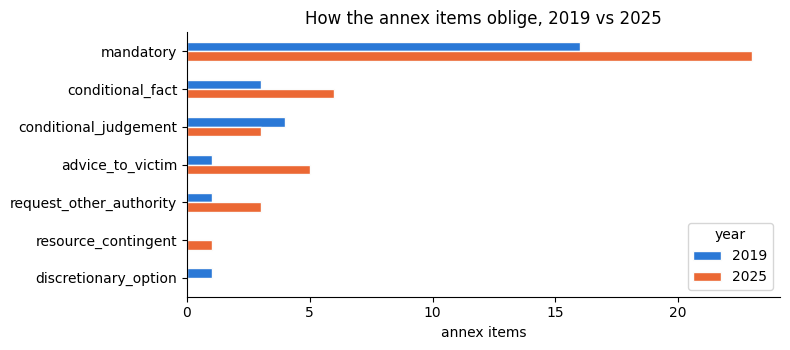

In [13]:
ct = pd.crosstab(m.modality, m.year).reindex(['mandatory', 'conditional_fact', 'conditional_judgement', 'advice_to_victim',
                                              'request_other_authority', 'resource_contingent', 'discretionary_option']).fillna(0)
ax = ct.plot.barh(color=['#2a78d6', '#eb6834'], figsize=(8, 3.6), edgecolor='#fcfcfb')
ax.invert_yaxis(); ax.set_xlabel('annex items'); ax.set_ylabel(''); ax.set_title('How the annex items oblige, 2019 vs 2025')
for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

### 9 · The 50 abstract pathways (combinations of rules, not cases)

In [14]:
paths = pd.DataFrame(D.enumerate_abstract_pathways())
display(paths.groupby(['year', 'first_vper_status']).size())
paths.head(8)

year  first_vper_status
2019  applies              29
      not_stated            1
2025  applies              19
      not_stated            1
dtype: int64

,pathway_id,year,assigned_category,officer_category,judicial_measures,override,first_vper_status,first_vper_max_days,first_vper_min_days,later_vper_status,later_vper_value,later_vper_unit,incident_instrument,case_status_rule,ordinary_inactivation,protection_floor_items,clause_ids,scope
0,P2019-no_-no_-noJM,2019,no_appreciable,no_appreciable,False,retained,not_stated,NaN,None,applies,90,days,VPER-C,inactivation_possible,cannot_determine,3,C19-5.3; C19-5.4; C19-POST; C19-2.6; C19-2.6.ii,abstract documentary pathway; not case-level evidence
1,P2019-no_-no_-JM,2019,no_appreciable,no_appreciable,True,retained,applies,7.0,None,applies,90,days,VPER-C,active,not_eligible,3,C19-5.4; C19-POST; C19-2.6,abstract documentary pathway; not case-level evidence
2,P2019-no_-low-noJM,2019,no_appreciable,low,False,raised,applies,7.0,None,applies,60,days,VPER-C,active_as_general_rule,cannot_determine,13,C19-5.3; C19-POST; C19-2.6; C19-2.6.ii; C19-2.6.iii,abstract documentary pathway; not case-level evidence
3,P2019-no_-low-JM,2019,no_appreciable,low,True,raised,applies,7.0,None,applies,60,days,VPER-C,active,not_eligible,13,C19-5.3; C19-POST; C19-2.6,abstract documentary pathway; not case-level evidence
4,P2019-no_-med-noJM,2019,no_appreciable,medium,False,raised,applies,7.0,None,applies,30,days,VPER-C,active_as_general_rule,not_eligible,20,C19-5.3; C19-POST; C19-2.5; C19-2.6,abstract documentary pathway; not case-level evidence
5,P2019-no_-med-JM,2019,no_appreciable,medium,True,raised,applies,7.0,None,applies,30,days,VPER-C,active,not_eligible,20,C19-5.3; C19-POST; C19-2.6,abstract documentary pathway; not case-level evidence
6,P2019-no_-hig-noJM,2019,no_appreciable,high,False,raised,applies,7.0,None,applies,7,days,VPER-C,active_as_general_rule,not_eligible,23,C19-5.3; C19-POST; C19-2.5; C19-2.6,abstract documentary pathway; not case-level evidence
7,P2019-no_-hig-JM,2019,no_appreciable,high,True,raised,applies,7.0,None,applies,7,days,VPER-C,active,not_eligible,23,C19-5.3; C19-POST; C19-2.6,abstract documentary pathway; not case-level evidence


### 10 · Findings, limits and questions for interviews

The full memo, with page references, is `FINDINGS_MEMO.md`. In short:

1. **Discretion over the automatic level is upward-only and old.** It dates from Instrucción 7/2016 at least, and VioGén-2 did not change it. The 2025 wording that the officer adopts the final decision "en acuerdo o desacuerdo" does not create a downward route. Any downward effect has to come through input coding.
2. **The low-risk restructuring is partly a relabelling.** At the procedural level, "Bajo without judicial measures" takes over the deadlines and intervals of the old "no apreciado", with a larger written floor and stricter conditions for closing the case.
3. **Within Bajo, a court's decision now sets the police schedule.** Whether judicial measures exist decides the first-VPER deadline (15 days or none), the interval (60 or 90 days), whether the case can be inactivated, and whether the aggressor is told his case is under police control and his prison movements are checked. In 2019 neither the bajo interval nor those two items depended on it. At Medio, the device request now depends on the system's special-relevance flag.
4. **Case closure is where the rules moved most, and 2024 matters as much as 2025.** Supervised cases came in 2/2024; the non-location threshold went 1 → 6 → 3 months; renunciation narrowed from any level (2019) to no apreciado/bajo/medio (2024) to Bajo/Medio (2025); exceptional inactivation moved from "podrá" to "se procederá"; ordinary inactivation now needs a positive finding.
5. **The accountability trail is uneven.** Exceptional-inactivation causes, capacity shortfalls and a missing supervision interview must be recorded. The protection measures actually taken only "should be recorded where possible". Courts now see the "No se sabe" answers, but receive a routine VPER only when the level rises, and no clause requires telling them about an ordinary inactivation.

**What the texts cannot tell us:** override frequency, delivery of measures, how "No se sabe" is scored, how Bajo cases split by judicial measures, and how supervised cases are handled in practice. See `INTERVIEW_PROMPTS.md`.

In [15]:
pd.DataFrame(UNCERTAINTY, columns=['item', 'type', 'question', 'current_evidence', 'confidence', 'how_to_resolve'])[['item', 'type', 'question', 'confidence']]

,item,type,question,confidence
0,U01,provenance,Authenticity of the 2025 PDF,medium-high
1,U02,provenance,Text of Instrucción 2/2024,medium
2,U03,provenance,"Texts of 8/2021, 11/2022, 1/2023, 7/2019, 12/2018",medium
3,U04,interpretation,Special relevance at Extremo: first VPER,medium
4,U05,interpretation,First VPER for Bajo without judicial measures (2025),high (that it is unstated)
5,U06,interpretation,Periodic VPER while supervised,high (that it is unstated)
6,U07,interpretation,"""Medidas Condicionadas""",medium
7,U08,interpretation,"Effective date vs. ""totalmente aplicable""",medium
8,U09,practice,Override frequency and reasons,unknown
9,U10,practice,Delivery of Annex measures,unknown
